# Projeto Final - Fundamentos de Machine Learning

**Integrantes do grupo:** Charlene, Cinthia, Cristiane e Douglas

**Base de dados:** `estudantes_desempenho.CSV`, versão traduzida para o português do *Student Performance Dataset* (disciplina de Língua Portuguesa, alunos do ensino secundário de duas escolas de Portugal: Gabriel Pereira - GP e Mousinho da Silveira - MS).

**Fonte original:** UCI Machine Learning Repository - https://archive.ics.uci.edu/dataset/320/student+performance (licença CC BY 4.0). Os dados foram coletados por P. Cortez e A. Silva (2008) a partir de boletins escolares e questionários respondidos pelos alunos.

**Tamanho:** 649 linhas (cada linha é um estudante) e 33 colunas.

---

# Etapa 1: Descrição do Problema

> **Enunciado da Especificação (Etapa 1):** *"1. Descrição do problema: o que vocês querem prever, classificar ou agrupar, e por que isso importa. Que decisão o modelo apoiaria?"*

### 1.1 O que queremos prever, classificar e agrupar

O tema do projeto é o desempenho escolar. Usamos a mesma base em três tarefas vistas na disciplina:

1. Regressão: prever a `Nota_Final` do aluno, que vai de 0 a 20 pontos.
2. Classificação: prever o `Risco_Reprovacao`. No sistema português a aprovação exige nota final maior ou igual a 10, então definimos `1` = reprovado (`Nota_Final < 10`) e `0` = aprovado (`Nota_Final >= 10`). Os reprovados são 100 dos 649 alunos (15,41%).
3. Agrupamento (K-Means + PCA): separar os alunos em perfis a partir de variáveis familiares e de comportamento, sem usar as notas, e depois verificar quais perfis concentram mais reprovação.

### 1.2 Por que isso importa e que decisão o modelo apoiaria

Quando a escola só descobre quem vai reprovar depois da nota final, não há mais o que fazer. A ideia é apoiar a coordenação pedagógica a decidir quais alunos devem receber reforço, tutoria ou acompanhamento com a família, já que esses recursos são limitados.

Pensamos em dois momentos de uso:

* Cenário A - início do ano letivo: a escola tem apenas o questionário do aluno e o histórico (por exemplo, reprovações anteriores). Não há notas do ano nem faltas do ano.
* Cenário B - fim do 2º período: a escola já tem as notas do 1º e do 2º período e quer saber quem ainda corre risco antes da avaliação final.

### 1.3 Dicionário de dados

A base não traz legenda própria. Os códigos numéricos abaixo vêm da documentação original do UCI (Cortez e Silva, 2008) e foram traduzidos por nós. Nas escalas de 1 a 5, a documentação define apenas os extremos; os valores 2, 3 e 4 são níveis intermediários.

| Nº | Coluna | O que representa | Tipo | Valores / códigos |
|---|---|---|---|---|
| 1 | `Escola` | Escola do aluno | Categórica binária | GP = Gabriel Pereira; MS = Mousinho da Silveira |
| 2 | `Sexo` | Sexo do aluno | Categórica binária | Feminino; Masculino |
| 3 | `Idade` | Idade em anos | Numérica | 15 a 22 |
| 4 | `Tipo_de_Endereco` | Onde o aluno mora | Categórica binária | Urbano; Rural |
| 5 | `Tamanho_da_Familia` | Número de pessoas na família | Categórica binária | Ate 3 (até 3 pessoas); Mais de 3 |
| 6 | `Situacao_dos_Pais` | Se os pais moram juntos | Categórica binária | Juntos; Separados |
| 7 | `Escolaridade_da_Mae` | Escolaridade da mãe | Ordinal | 0 = nenhuma; 1 = ensino primário (até o 4º ano); 2 = do 5º ao 9º ano; 3 = ensino secundário (equivale ao ensino médio); 4 = ensino superior |
| 8 | `Escolaridade_do_Pai` | Escolaridade do pai | Ordinal | mesma escala da mãe (0 a 4) |
| 9 | `Ocupacao_da_Mae` | Profissão da mãe | Categórica nominal | Professor(a); Saude; Servicos (serviços públicos, como administrativo ou polícia); Em casa; Outro |
| 10 | `Ocupacao_do_Pai` | Profissão do pai | Categórica nominal | mesmas categorias da mãe |
| 11 | `Motivo_da_Escolha_da_Escola` | Por que escolheu a escola | Categórica nominal | Proximidade de casa; Reputacao da escola; Preferencia pelo curso; Outro |
| 12 | `Responsavel` | Responsável pelo aluno | Categórica nominal | Mae; Pai; Outro |
| 13 | `Tempo_de_Deslocamento` | Tempo de casa até a escola | Ordinal | 1 = menos de 15 min; 2 = 15 a 30 min; 3 = 30 min a 1 hora; 4 = mais de 1 hora |
| 14 | `Tempo_de_Estudo_Semanal` | Horas de estudo por semana | Ordinal | 1 = menos de 2 h; 2 = 2 a 5 h; 3 = 5 a 10 h; 4 = mais de 10 h |
| 15 | `Reprovacoes_Anteriores` | Reprovações em anos anteriores | Numérica discreta | 0 = nenhuma; 1; 2; 3 = três ou mais |
| 16 | `Apoio_Educacional_da_Escola` | Recebe apoio extra da escola | Binária | Sim; Não |
| 17 | `Apoio_Educacional_Familiar` | Recebe apoio da família nos estudos | Binária | Sim; Não |
| 18 | `Aulas_Particulares_Pagas` | Faz aulas particulares pagas da disciplina | Binária | Sim; Não |
| 19 | `Atividades_Extracurriculares` | Faz atividades extracurriculares | Binária | Sim; Não |
| 20 | `Frequentou_Educacao_Infantil` | Frequentou creche/pré-escola | Binária | Sim; Não |
| 21 | `Pretende_Cursar_Ensino_Superior` | Quer fazer faculdade | Binária | Sim; Não |
| 22 | `Acesso_a_Internet_em_Casa` | Tem internet em casa | Binária | Sim; Não |
| 23 | `Relacionamento_Amoroso` | Está namorando | Binária | Sim; Não |
| 24 | `Qualidade_das_Relacoes_Familiares` | Como avalia a relação com a família | Ordinal | 1 = muito ruim ... 5 = excelente |
| 25 | `Tempo_Livre_Apos_a_Escola` | Tempo livre depois da aula | Ordinal | 1 = muito pouco ... 5 = muito |
| 26 | `Frequencia_de_Saidas_com_Amigos` | Quanto sai com os amigos | Ordinal | 1 = muito pouco ... 5 = muito |
| 27 | `Consumo_de_Alcool_em_Dias_Uteis` | Consumo de álcool de segunda a sexta | Ordinal | 1 = muito baixo ... 5 = muito alto |
| 28 | `Consumo_de_Alcool_no_Fim_de_Semana` | Consumo de álcool no fim de semana | Ordinal | 1 = muito baixo ... 5 = muito alto |
| 29 | `Estado_de_Saude_Atual` | Como avalia a própria saúde | Ordinal | 1 = muito ruim ... 5 = muito bom |
| 30 | `Numero_de_Faltas` | Faltas no ano letivo | Numérica | 0 a 93 na documentação (nesta base vai até 32) |
| 31 | `Nota_1o_Periodo` | Nota do 1º período | Numérica | 0 a 20 |
| 32 | `Nota_2o_Periodo` | Nota do 2º período | Numérica | 0 a 20 |
| 33 | `Nota_Final` | Nota final do ano (3º período) | Numérica - alvo da regressão | 0 a 20 (aprovado com 10 ou mais) |

Colunas que nós criamos durante o projeto:

| Coluna criada | Significado | Códigos |
|---|---|---|
| `Situacao_Final` | Situação do aluno, usada só na análise exploratória | Aprovado (nota final >= 10); Reprovado (nota final < 10) |
| `Risco_Reprovacao` | Alvo da classificação | 1 = reprovado; 0 = aprovado |
| `Cluster` | Perfil encontrado pelo K-Means | número do grupo (0, 1, 2...), sem ordem de importância; o significado de cada grupo é descrito na Etapa 5 |

---

# Etapa 2: Pré-processamento e Análise Exploratória dos Dados (EDA)

> **Enunciado da Especificação (Etapa 2):** *"2. Pré-processamento e análise exploratória: tratamento de valores ausentes, normalização ou transformação, codificação de variáveis categóricas e uma EDA que justifique essas escolhas."*

Nesta etapa conferimos a estrutura e a qualidade da base (ausentes, duplicados, tipos, valores fora da escala) e olhamos as relações entre as variáveis e a nota final. Aqui nada é ajustado nos dados: a codificação e a padronização são definidas no fim da etapa, mas só são aplicadas depois da divisão treino/teste (Etapas 3 e 4), dentro de um `Pipeline`.

## 2.1 Bibliotecas

Os resultados deste notebook foram gerados com o scikit-learn 1.9.1. Em outras versões, o Random Forest pode montar as árvores de outro jeito e mudar alguns números das tabelas. No Colab, a célula abaixo instala essa versão automaticamente. Fora do Colab, ela só confere a versão instalada e avisa se for diferente.

In [1]:
import sys
from importlib.metadata import version

VERSAO_USADA = "1.9.1"
versao_instalada = version("scikit-learn")

if versao_instalada != VERSAO_USADA and "google.colab" in sys.modules:
    %pip install -q scikit-learn==1.9.1
elif versao_instalada != VERSAO_USADA:
    print(f"Aviso: o texto deste notebook foi escrito com os resultados do scikit-learn {VERSAO_USADA}, "
          f"mas aqui está instalada a versão {versao_instalada}. Alguns números do Random Forest podem mudar.")
else:
    print("scikit-learn", versao_instalada)

scikit-learn 1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (make_scorer, mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SEMENTE = 42  # mesma semente em todo o notebook para os resultados se repetirem

## 2.2 Carregamento do CSV

O arquivo usa ponto e vírgula como separador e acentuação em `latin-1`. O CSV precisa estar na mesma pasta do notebook (no Colab, enviado pelo menu de arquivos). A busca ignora maiúsculas e minúsculas na extensão (`.CSV` ou `.csv`).

In [3]:
from pathlib import Path

encontrados = [p for p in Path(".").iterdir() if p.name.lower() == "estudantes_desempenho.csv"]
if not encontrados:
    raise FileNotFoundError("Arquivo estudantes_desempenho.CSV não encontrado. "
                            "Coloque o CSV na mesma pasta deste notebook e rode novamente.")

arquivo = encontrados[0]
df = pd.read_csv(arquivo, sep=";", encoding="latin-1")
df.head()

,Escola,Sexo,Idade,Tipo_de_Endereco,Tamanho_da_Familia,Situacao_dos_Pais,Escolaridade_da_Mae,Escolaridade_do_Pai,Ocupacao_da_Mae,Ocupacao_do_Pai,Motivo_da_Escolha_da_Escola,Responsavel,Tempo_de_Deslocamento,Tempo_de_Estudo_Semanal,Reprovacoes_Anteriores,Apoio_Educacional_da_Escola,Apoio_Educacional_Familiar,Aulas_Particulares_Pagas,Atividades_Extracurriculares,Frequentou_Educacao_Infantil,Pretende_Cursar_Ensino_Superior,Acesso_a_Internet_em_Casa,Relacionamento_Amoroso,Qualidade_das_Relacoes_Familiares,Tempo_Livre_Apos_a_Escola,Frequencia_de_Saidas_com_Amigos,Consumo_de_Alcool_em_Dias_Uteis,Consumo_de_Alcool_no_Fim_de_Semana,Estado_de_Saude_Atual,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
0,GP,Feminino,18,Urbano,Mais_de_3,Separados,4,4,Em_casa,Professor(a),Preferencia_pelo_curso,Mae,2,2,0,Sim,Não,Não,Não,Sim,Sim,Não,Não,4,3,4,1,1,3,4,0,11,11
1,GP,Feminino,17,Urbano,Mais_de_3,Juntos,1,1,Em_casa,Outro,Preferencia_pelo_curso,Pai,1,2,0,Não,Sim,Não,Não,Não,Sim,Sim,Não,5,3,3,1,1,3,2,9,11,11
2,GP,Feminino,15,Urbano,Ate_3,Juntos,1,1,Em_casa,Outro,Outro,Mae,1,2,0,Sim,Não,Não,Não,Sim,Sim,Sim,Não,4,3,2,2,3,3,6,12,13,12
3,GP,Feminino,15,Urbano,Mais_de_3,Juntos,4,2,Saude,Servicos,Proximidade_de_casa,Mae,1,3,0,Não,Sim,Não,Sim,Sim,Sim,Sim,Sim,3,2,2,1,1,5,0,14,14,14
4,GP,Feminino,16,Urbano,Mais_de_3,Juntos,3,3,Outro,Outro,Proximidade_de_casa,Pai,1,2,0,Não,Sim,Não,Não,Sim,Sim,Não,Não,4,3,2,1,2,5,0,11,13,13


## 2.3 Dimensão da base

In [4]:
print(f"Estudantes (linhas): {df.shape[0]}")
print(f"Variáveis (colunas): {df.shape[1]}")

Estudantes (linhas): 649
Variáveis (colunas): 33


## 2.4 Tipos das variáveis

Várias colunas numéricas são, na verdade, códigos de escala (ver o dicionário na seção 1.3). Por exemplo, `Tempo_de_Estudo_Semanal = 3` não quer dizer 3 horas, e sim "de 5 a 10 horas".

In [5]:
df.columns = df.columns.str.strip()
colunas_numericas = df.select_dtypes(include="number").columns.tolist()
colunas_categoricas = df.select_dtypes(exclude="number").columns.tolist()

df.info()
print("\nNuméricas:", len(colunas_numericas), "| Categóricas:", len(colunas_categoricas))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Escola                              649 non-null    object
 1   Sexo                                649 non-null    object
 2   Idade                               649 non-null    int64 
 3   Tipo_de_Endereco                    649 non-null    object
 4   Tamanho_da_Familia                  649 non-null    object
 5   Situacao_dos_Pais                   649 non-null    object
 6   Escolaridade_da_Mae                 649 non-null    int64 
 7   Escolaridade_do_Pai                 649 non-null    int64 
 8   Ocupacao_da_Mae                     649 non-null    object
 9   Ocupacao_do_Pai                     649 non-null    object
 10  Motivo_da_Escolha_da_Escola         649 non-null    object
 11  Responsavel                         649 non-null    object

## 2.5 Limpeza dos textos

Tiramos espaços nas pontas e trocamos `_` por espaço nos valores de texto (ex.: `Mais_de_3` vira `Mais de 3`), só para facilitar a leitura das tabelas e gráficos.

In [6]:
for coluna in colunas_categoricas:
    df[coluna] = df[coluna].str.strip().str.replace("_", " ", regex=False)

## 2.6 Valores ausentes

Procuramos tanto nulos de verdade quanto marcadores escritos como texto (`"NA"`, `"?"`, `"-"` etc.), que o pandas não reconhece como ausentes.

In [7]:
marcadores_texto = ["", " ", "NA", "N/A", "null", "Null", "?", "-"]

ausentes = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Marcadores de texto": df[colunas_categoricas].isin(marcadores_texto).sum().reindex(df.columns, fill_value=0),
})
print("Total de nulos:", int(ausentes["Nulos"].sum()))
print("Total de marcadores de texto:", int(ausentes["Marcadores de texto"].sum()))
ausentes[ausentes.sum(axis=1) > 0]

Total de nulos: 0
Total de marcadores de texto: 0


,Nulos,Marcadores de texto


A base não tem nenhum valor ausente, nem disfarçado de texto. Por isso não foi preciso imputar nem remover linhas. Mesmo assim, deixamos o tratamento preparado no pipeline (`handle_unknown="ignore"` no codificador) para categorias novas que apareçam no teste.

## 2.7 Duplicidades

Como não há identificador de aluno, conferimos se existem linhas idênticas.

In [8]:
print("Linhas completamente duplicadas:", df.duplicated().sum())

Linhas completamente duplicadas: 0


## 2.8 Categorias

In [9]:
for coluna in colunas_categoricas:
    contagem = df[coluna].value_counts()
    print(f"{coluna}: " + " | ".join(f"{k} = {v}" for k, v in contagem.items()))

Escola: GP = 423 | MS = 226
Sexo: Feminino = 383 | Masculino = 266
Tipo_de_Endereco: Urbano = 452 | Rural = 197
Tamanho_da_Familia: Mais de 3 = 457 | Ate 3 = 192
Situacao_dos_Pais: Juntos = 569 | Separados = 80
Ocupacao_da_Mae: Outro = 258 | Servicos = 136 | Em casa = 135 | Professor(a) = 72 | Saude = 48
Ocupacao_do_Pai: Outro = 367 | Servicos = 181 | Em casa = 42 | Professor(a) = 36 | Saude = 23
Motivo_da_Escolha_da_Escola: Preferencia pelo curso = 285 | Proximidade de casa = 149 | Reputacao da escola = 143 | Outro = 72
Responsavel: Mae = 455 | Pai = 153 | Outro = 41
Apoio_Educacional_da_Escola: Não = 581 | Sim = 68
Apoio_Educacional_Familiar: Sim = 398 | Não = 251
Aulas_Particulares_Pagas: Não = 610 | Sim = 39
Atividades_Extracurriculares: Não = 334 | Sim = 315
Frequentou_Educacao_Infantil: Sim = 521 | Não = 128
Pretende_Cursar_Ensino_Superior: Sim = 580 | Não = 69
Acesso_a_Internet_em_Casa: Sim = 498 | Não = 151
Relacionamento_Amoroso: Não = 410 | Sim = 239


Treze variáveis de texto têm só duas categorias (sim/não, urbano/rural etc.) e quatro têm de três a cinco categorias (ocupações, motivo da escolha e responsável). Algumas são bem desequilibradas: só 39 alunos fazem aulas particulares pagas e só 68 recebem apoio extra da escola.

## 2.9 Estatísticas descritivas e leitura dos códigos

In [10]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Idade,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Escolaridade_da_Mae,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Escolaridade_do_Pai,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
Tempo_de_Deslocamento,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
Tempo_de_Estudo_Semanal,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
Reprovacoes_Anteriores,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
Qualidade_das_Relacoes_Familiares,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
Tempo_Livre_Apos_a_Escola,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
Frequencia_de_Saidas_com_Amigos,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Consumo_de_Alcool_em_Dias_Uteis,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


Para ler as médias acima é preciso lembrar dos códigos. A tabela a seguir mostra, para cada variável codificada, o significado de cada número e quantos alunos estão em cada nível.

In [11]:
def escala_1a5(baixo, alto):
    return {1: f"1 - {baixo}", 2: "2", 3: "3", 4: "4", 5: f"5 - {alto}"}

escolaridade = {0: "Nenhuma", 1: "Primário (até 4º ano)", 2: "5º ao 9º ano",
                3: "Secundário (ensino médio)", 4: "Superior"}

dicionario_codigos = {
    "Escolaridade_da_Mae": escolaridade,
    "Escolaridade_do_Pai": escolaridade,
    "Tempo_de_Deslocamento": {1: "Menos de 15 min", 2: "15 a 30 min", 3: "30 min a 1 h", 4: "Mais de 1 h"},
    "Tempo_de_Estudo_Semanal": {1: "Menos de 2 h", 2: "2 a 5 h", 3: "5 a 10 h", 4: "Mais de 10 h"},
    "Reprovacoes_Anteriores": {0: "Nenhuma", 1: "1", 2: "2", 3: "3 ou mais"},
    "Qualidade_das_Relacoes_Familiares": escala_1a5("Muito ruim", "Excelente"),
    "Tempo_Livre_Apos_a_Escola": escala_1a5("Muito pouco", "Muito"),
    "Frequencia_de_Saidas_com_Amigos": escala_1a5("Muito pouco", "Muito"),
    "Consumo_de_Alcool_em_Dias_Uteis": escala_1a5("Muito baixo", "Muito alto"),
    "Consumo_de_Alcool_no_Fim_de_Semana": escala_1a5("Muito baixo", "Muito alto"),
    "Estado_de_Saude_Atual": escala_1a5("Muito ruim", "Muito bom"),
}

linhas = []
for coluna, mapa in dicionario_codigos.items():
    contagem = df[coluna].value_counts()
    for codigo, significado in mapa.items():
        linhas.append([coluna, codigo, significado, int(contagem.get(codigo, 0))])

tabela_codigos = pd.DataFrame(linhas, columns=["Variável", "Código", "Significado", "Alunos"])
tabela_codigos

,Variável,Código,Significado,Alunos
0,Escolaridade_da_Mae,0,Nenhuma,6
1,Escolaridade_da_Mae,1,Primário (até 4º ano),143
2,Escolaridade_da_Mae,2,5º ao 9º ano,186
3,Escolaridade_da_Mae,3,Secundário (ensino médio),139
4,Escolaridade_da_Mae,4,Superior,175
5,Escolaridade_do_Pai,0,Nenhuma,7
6,Escolaridade_do_Pai,1,Primário (até 4º ano),174
7,Escolaridade_do_Pai,2,5º ao 9º ano,209
8,Escolaridade_do_Pai,3,Secundário (ensino médio),131
9,Escolaridade_do_Pai,4,Superior,128


In [12]:
df.describe(exclude="number").T

,count,unique,top,freq
Escola,649,2,GP,423
Sexo,649,2,Feminino,383
Tipo_de_Endereco,649,2,Urbano,452
Tamanho_da_Familia,649,2,Mais de 3,457
Situacao_dos_Pais,649,2,Juntos,569
Ocupacao_da_Mae,649,5,Outro,258
Ocupacao_do_Pai,649,5,Outro,367
Motivo_da_Escolha_da_Escola,649,4,Preferencia pelo curso,285
Responsavel,649,3,Mae,455
Apoio_Educacional_da_Escola,649,2,Não,581


Alguns pontos que já aparecem nas estatísticas: a média de `Reprovacoes_Anteriores` é 0,22 porque a grande maioria nunca reprovou; `Tempo_de_Estudo_Semanal` tem média 1,93, ou seja, a maior parte estuda menos de 5 horas por semana (códigos 1 e 2); e `Numero_de_Faltas` tem média 3,66, mas máximo 32, o que indica uma cauda longa.

## 2.10 Verificação de valores fora da escala

O `describe()` da seção 2.9 mostra o mínimo e o máximo de cada coluna, mas não diz se esses valores são permitidos. Aqui comparamos o mínimo e o máximo de cada coluna com a faixa definida no dicionário (seção 1.3) e contamos quantos valores ficam fora dela.

In [13]:
faixas = {
    "Idade": (15, 22), "Escolaridade_da_Mae": (0, 4), "Escolaridade_do_Pai": (0, 4),
    "Tempo_de_Deslocamento": (1, 4), "Tempo_de_Estudo_Semanal": (1, 4), "Reprovacoes_Anteriores": (0, 3),
    "Qualidade_das_Relacoes_Familiares": (1, 5), "Tempo_Livre_Apos_a_Escola": (1, 5),
    "Frequencia_de_Saidas_com_Amigos": (1, 5), "Consumo_de_Alcool_em_Dias_Uteis": (1, 5),
    "Consumo_de_Alcool_no_Fim_de_Semana": (1, 5), "Estado_de_Saude_Atual": (1, 5),
    "Numero_de_Faltas": (0, 93), "Nota_1o_Periodo": (0, 20), "Nota_2o_Periodo": (0, 20), "Nota_Final": (0, 20),
}
verificacao = pd.DataFrame(
    [[c, mn, mx, int(df[c].min()), int(df[c].max()), int(((df[c] < mn) | (df[c] > mx)).sum())]
     for c, (mn, mx) in faixas.items()],
    columns=["Variável", "Mín. permitido", "Máx. permitido", "Mín. na base", "Máx. na base", "Fora da faixa"],
)
verificacao

,Variável,Mín. permitido,Máx. permitido,Mín. na base,Máx. na base,Fora da faixa
0,Idade,15,22,15,22,0
1,Escolaridade_da_Mae,0,4,0,4,0
2,Escolaridade_do_Pai,0,4,0,4,0
3,Tempo_de_Deslocamento,1,4,1,4,0
4,Tempo_de_Estudo_Semanal,1,4,1,4,0
5,Reprovacoes_Anteriores,0,3,0,3,0
6,Qualidade_das_Relacoes_Familiares,1,5,1,5,0
7,Tempo_Livre_Apos_a_Escola,1,5,1,5,0
8,Frequencia_de_Saidas_com_Amigos,1,5,1,5,0
9,Consumo_de_Alcool_em_Dias_Uteis,1,5,1,5,0


Nenhum valor está fora da faixa da documentação.

## 2.11 Distribuição das notas

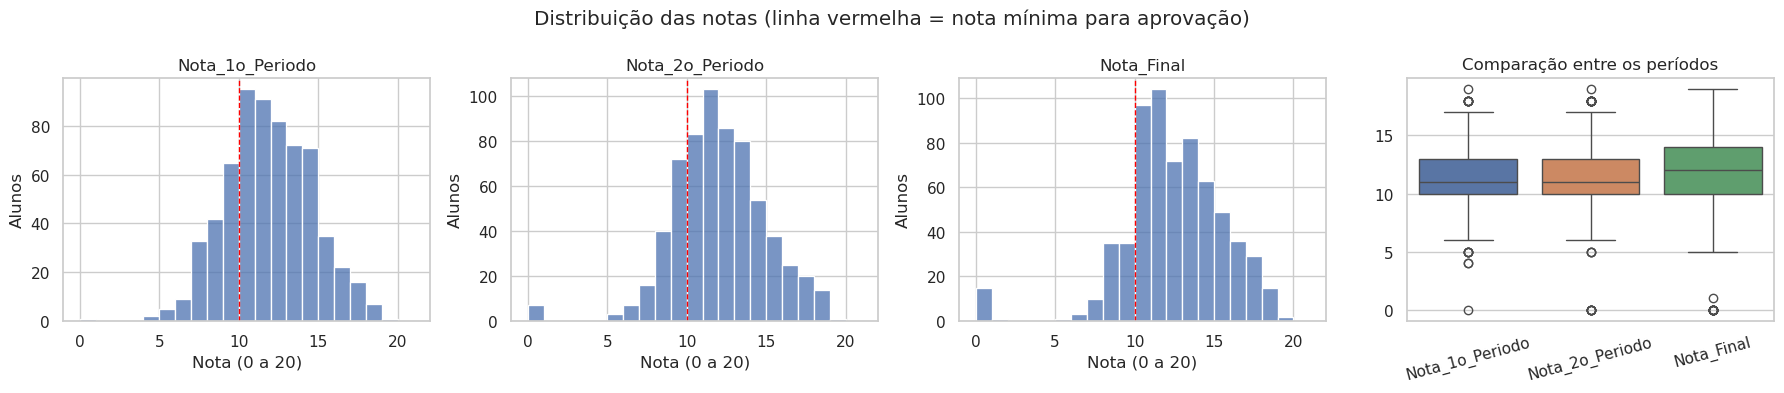

,count,mean,std,min,25%,50%,75%,max
Nota_1o_Periodo,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0
Nota_2o_Periodo,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0
Nota_Final,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0


In [14]:
colunas_notas = ["Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, coluna in zip(axes[:3], colunas_notas):
    sns.histplot(df[coluna], bins=21, binrange=(0, 21), ax=ax)
    ax.axvline(10, color="red", linestyle="--", linewidth=1)
    ax.set_title(coluna); ax.set_xlabel("Nota (0 a 20)"); ax.set_ylabel("Alunos")
sns.boxplot(data=df[colunas_notas], ax=axes[3])
axes[3].set_title("Comparação entre os períodos"); axes[3].tick_params(axis="x", rotation=15)
plt.suptitle("Distribuição das notas (linha vermelha = nota mínima para aprovação)")
plt.tight_layout(); plt.show()

df[colunas_notas].describe().T.round(2)

As notas se concentram entre 10 e 14 nos três períodos (mediana 11 no 1º e no 2º, 12 na final). O que chama atenção é a cauda à esquerda: na nota final há um grupo de alunos com nota zero, separado do restante da distribuição. Investigamos esses casos abaixo.

In [15]:
zeros = pd.DataFrame({
    "Alunos com nota 0": (df[colunas_notas] == 0).sum(),
    "% da base": ((df[colunas_notas] == 0).mean() * 100).round(2),
})
display(zeros)

nota_zero = df[df["Nota_Final"] == 0]
print("Escola dos alunos com nota final 0:", nota_zero["Escola"].value_counts().to_dict())
print("Faltas desses alunos:", nota_zero["Numero_de_Faltas"].value_counts().to_dict())
nota_zero[["Escola", "Idade", "Numero_de_Faltas", "Nota_1o_Periodo", "Nota_2o_Periodo", "Nota_Final"]]

,Alunos com nota 0,% da base
Nota_1o_Periodo,1,0.15
Nota_2o_Periodo,7,1.08
Nota_Final,15,2.31


Escola dos alunos com nota final 0: {'MS': 14, 'GP': 1}
Faltas desses alunos: {0: 15}


,Escola,Idade,Numero_de_Faltas,Nota_1o_Periodo,Nota_2o_Periodo,Nota_Final
163,GP,18,0,11,9,0
440,MS,16,0,7,0,0
519,MS,16,0,8,7,0
563,MS,17,0,7,0,0
567,MS,18,0,4,0,0
583,MS,18,0,8,6,0
586,MS,17,0,8,8,0
597,MS,18,0,9,0,0
603,MS,18,0,5,0,0
605,MS,19,0,5,0,0


São 15 alunos com nota final zero (2,31%). Todos têm zero faltas e 14 deles são da escola MS. Um aluno que tirou 7 ou 8 nos períodos anteriores dificilmente zera a prova final; o mais provável é que tenha deixado a escola ou não feito a avaliação (a base não diz qual dos dois). O zero de faltas também sugere que a contagem parou quando o aluno saiu.

Decisão: mantivemos esses alunos. Para a escola, um aluno que abandona é exatamente o caso que ela quer identificar, e retirar esses registros deixaria o modelo otimista demais. Em compensação, esses casos inflam o erro da regressão (o modelo não tem como saber de antemão quem vai abandonar), e isso aparece na avaliação.

## 2.12 Faltas e valores atípicos

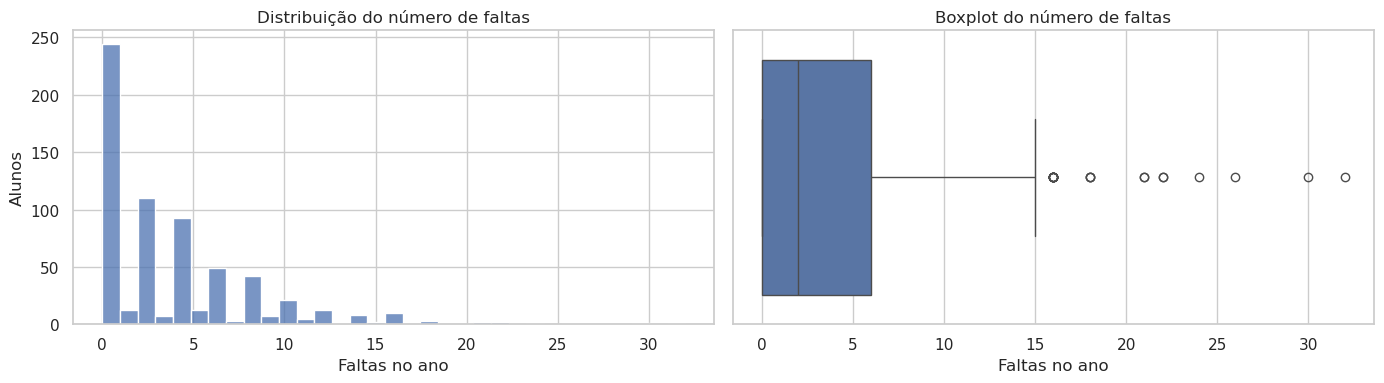

Q1 = 0 | Q3 = 6 | limite superior pelo IQR = 15 faltas
Alunos acima do limite: 21
Nota final média desses alunos: 10.76 (base toda: 11.91)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Numero_de_Faltas"], bins=33, ax=axes[0])
axes[0].set_title("Distribuição do número de faltas"); axes[0].set_xlabel("Faltas no ano"); axes[0].set_ylabel("Alunos")
sns.boxplot(x=df["Numero_de_Faltas"], ax=axes[1])
axes[1].set_title("Boxplot do número de faltas"); axes[1].set_xlabel("Faltas no ano")
plt.tight_layout(); plt.show()

q1, q3 = df["Numero_de_Faltas"].quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
atipicos = df[df["Numero_de_Faltas"] > limite_superior]
print(f"Q1 = {q1:.0f} | Q3 = {q3:.0f} | limite superior pelo IQR = {limite_superior:.0f} faltas")
print(f"Alunos acima do limite: {len(atipicos)}")
print(f"Nota final média desses alunos: {atipicos['Nota_Final'].mean():.2f} (base toda: {df['Nota_Final'].mean():.2f})")

A distribuição das faltas é bem assimétrica: metade dos alunos tem até 2 faltas e 75% tem até 6, mas o máximo chega a 32. Pelo critério do IQR, 21 alunos têm mais de 15 faltas. Esses valores são possíveis no contexto escolar (estão bem abaixo do máximo de 93 da documentação), então não removemos nem cortamos esses registros. Como as faltas registradas são o total do ano inteiro, elas não entram nos modelos de previsão (ver Etapa 3), mas são usadas na descrição dos perfis do agrupamento.

## 2.13 Tempo de estudo e reprovações anteriores

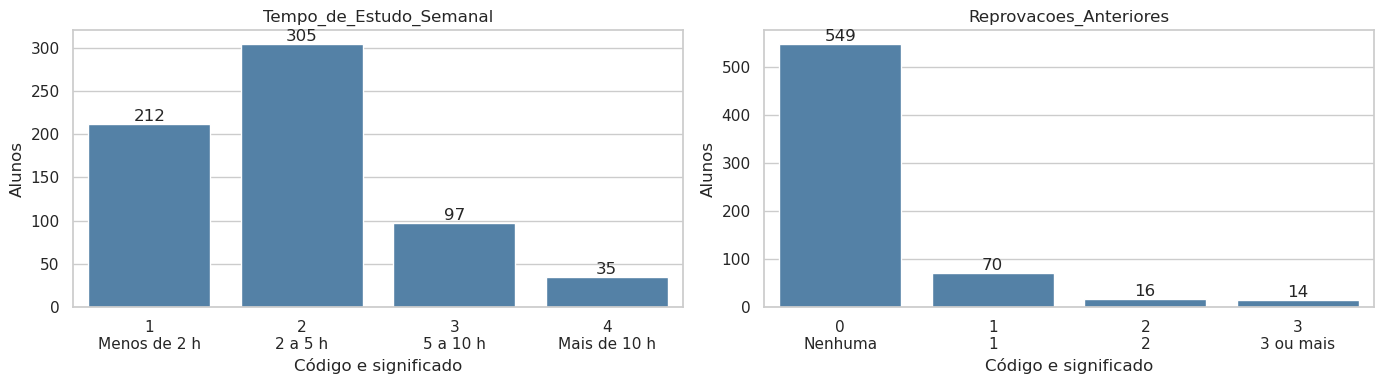

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, coluna in zip(axes, ["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]):
    ordem = sorted(df[coluna].unique())
    sns.countplot(x=df[coluna], order=ordem, ax=ax, color="steelblue")
    ax.set_xticks(range(len(ordem)))
    ax.set_xticklabels([f"{c}\n{dicionario_codigos[coluna][c]}" for c in ordem])
    ax.set_title(coluna); ax.set_xlabel("Código e significado"); ax.set_ylabel("Alunos")
    ax.bar_label(ax.containers[0])
plt.tight_layout(); plt.show()

517 dos 649 alunos (cerca de 80%) estudam menos de 5 horas por semana (códigos 1 e 2), e só 35 estudam mais de 10 horas. Quanto às reprovações, 549 alunos (84,6%) nunca reprovaram e 100 têm de 1 a 3 reprovações no histórico.

## 2.14 Relações com a nota final

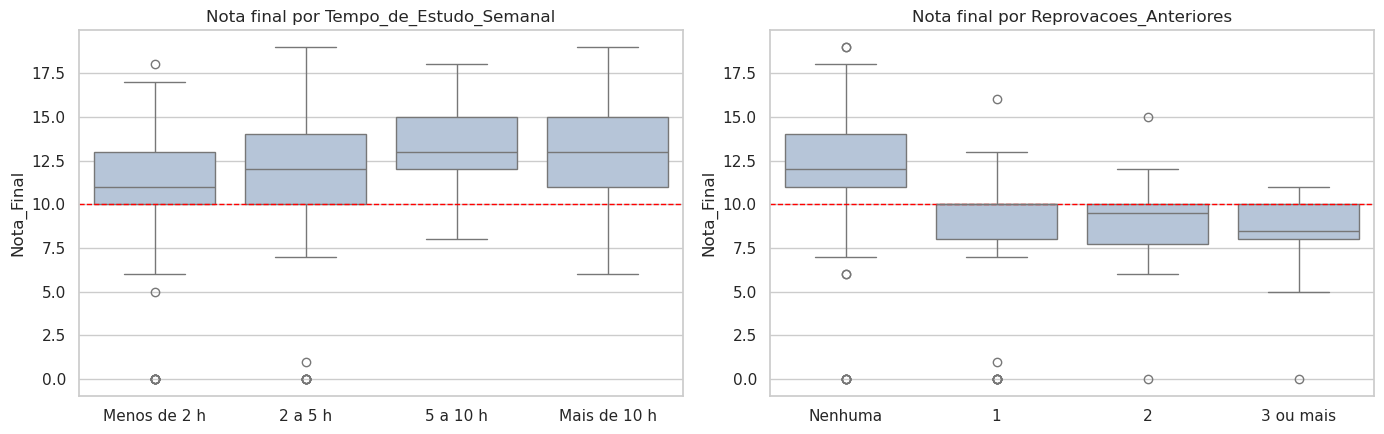

,Alunos,Média da nota final,Mediana
Tempo_de_Estudo_Semanal,,,
1 - Menos de 2 h,212,10.84,11.0
2 - 2 a 5 h,305,12.09,12.0
3 - 5 a 10 h,97,13.23,13.0
4 - Mais de 10 h,35,13.06,13.0


,Alunos,Média da nota final,Mediana
Reprovacoes_Anteriores,,,
0 - Nenhuma,549,12.51,12.0
1 - 1,70,8.64,10.0
2 - 2,16,8.81,9.5
3 - 3 ou mais,14,8.07,8.5


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, coluna in zip(axes, ["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]):
    ordem = sorted(df[coluna].unique())
    sns.boxplot(x=df[coluna], y=df["Nota_Final"], order=ordem, ax=ax, color="lightsteelblue")
    ax.set_xticks(range(len(ordem)))
    ax.set_xticklabels([dicionario_codigos[coluna][c] for c in ordem])
    ax.axhline(10, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Nota final por {coluna}"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

for coluna in ["Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores"]:
    resumo = df.groupby(coluna)["Nota_Final"].agg(["count", "mean", "median"]).round(2)
    resumo.index = [f"{c} - {dicionario_codigos[coluna][c]}" for c in resumo.index]
    resumo.columns = ["Alunos", "Média da nota final", "Mediana"]
    resumo.index.name = coluna
    display(resumo)

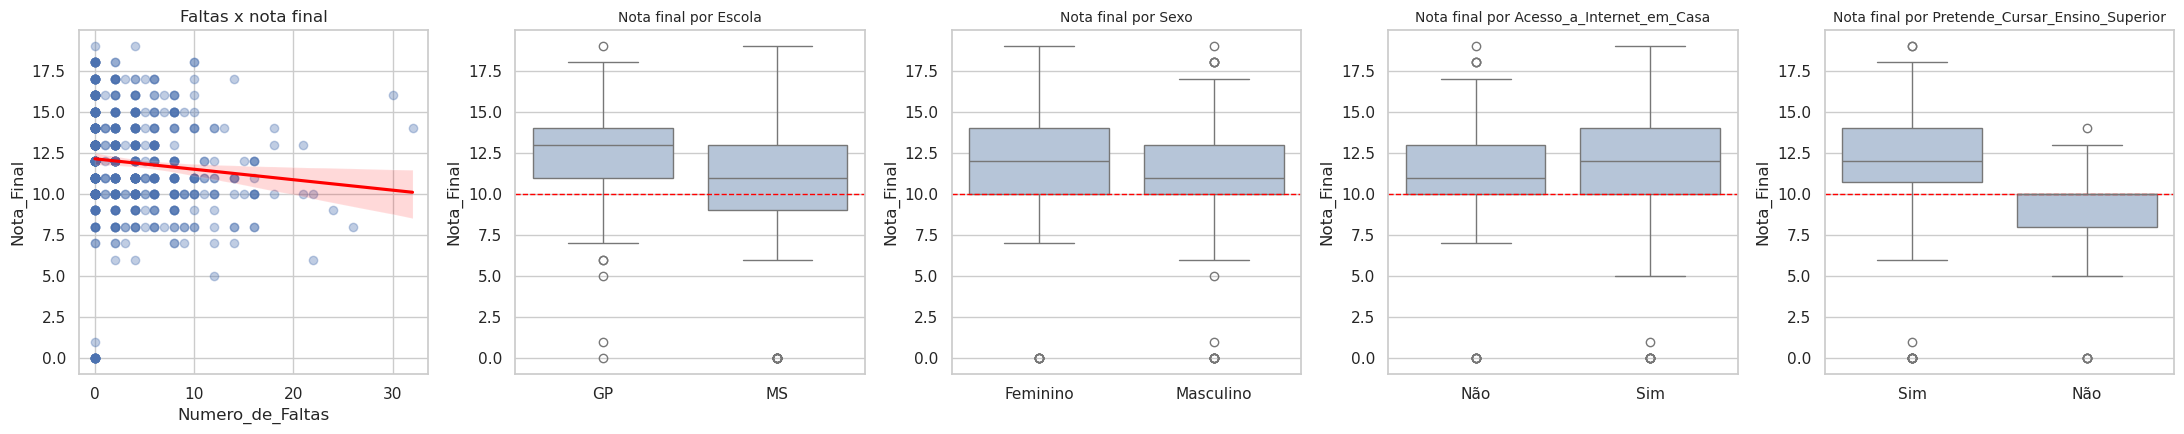

Escola {'GP': 12.58, 'MS': 10.65}
Sexo {'Feminino': 12.25, 'Masculino': 11.41}
Acesso_a_Internet_em_Casa {'Não': 11.03, 'Sim': 12.17}
Pretende_Cursar_Ensino_Superior {'Não': 8.8, 'Sim': 12.28}


In [19]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
sns.regplot(data=df, x="Numero_de_Faltas", y="Nota_Final", ax=axes[0],
            scatter_kws={"alpha": 0.35}, line_kws={"color": "red"})
axes[0].set_title("Faltas x nota final")
for ax, coluna in zip(axes[1:], ["Escola", "Sexo", "Acesso_a_Internet_em_Casa", "Pretende_Cursar_Ensino_Superior"]):
    sns.boxplot(data=df, x=coluna, y="Nota_Final", ax=ax, color="lightsteelblue")
    ax.axhline(10, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Nota final por {coluna}", fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()

for coluna in ["Escola", "Sexo", "Acesso_a_Internet_em_Casa", "Pretende_Cursar_Ensino_Superior"]:
    print(coluna, df.groupby(coluna)["Nota_Final"].mean().round(2).to_dict())

A nota final sobe com o tempo de estudo: a média vai de 10,84 para quem estuda menos de 2 h por semana até 13,23 para quem estuda de 5 a 10 h (o grupo de mais de 10 h, com só 35 alunos, fica em 13,06). O efeito das reprovações anteriores é ainda maior: quem nunca reprovou tem média 12,51, e quem já reprovou fica entre 8,07 e 8,81, abaixo da nota mínima para aprovação.

As faltas têm relação negativa com a nota, mas fraca: a reta cai pouco e os pontos estão muito espalhados. Entre as variáveis de texto, as maiores diferenças estão em querer cursar o ensino superior (média 12,28 contra 8,80) e na escola (GP 12,58 contra MS 10,65). Sexo e acesso à internet mostram diferenças menores, de cerca de 1 ponto.

## 2.15 Correlação

Usamos a correlação de Spearman, que trabalha com a ordem dos valores. Ela é mais adequada que a de Pearson aqui, porque boa parte das variáveis são escalas ordinais (1 a 5, 0 a 4) e não medidas contínuas.

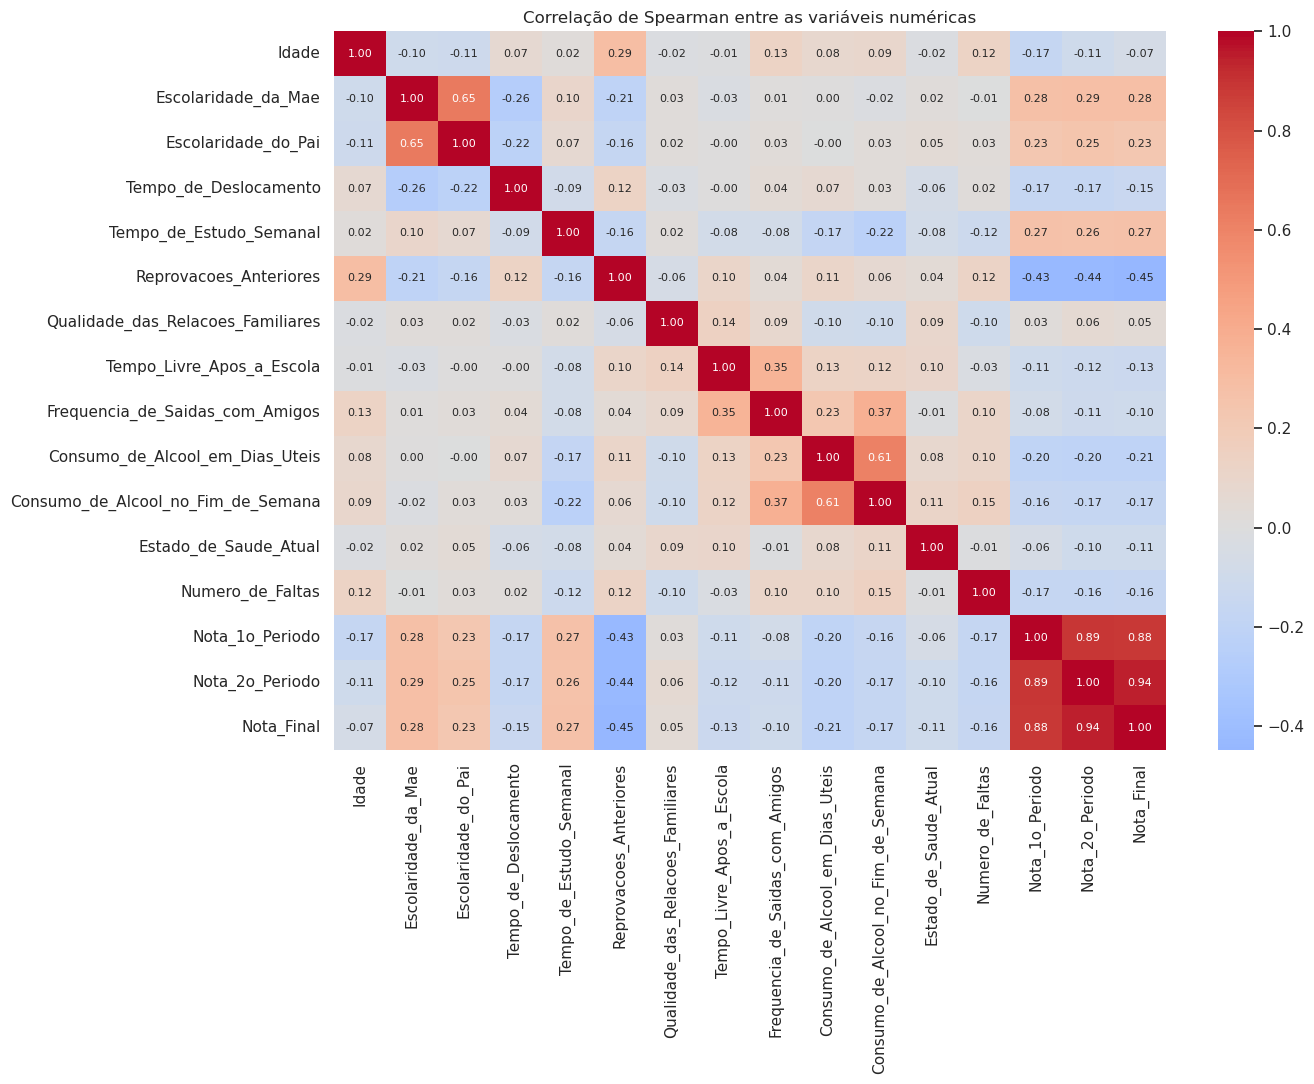

Reprovacoes_Anteriores               -0.448
Consumo_de_Alcool_em_Dias_Uteis      -0.208
Consumo_de_Alcool_no_Fim_de_Semana   -0.171
Numero_de_Faltas                     -0.159
Tempo_de_Deslocamento                -0.147
Tempo_Livre_Apos_a_Escola            -0.128
Estado_de_Saude_Atual                -0.106
Frequencia_de_Saidas_com_Amigos      -0.105
Idade                                -0.066
Qualidade_das_Relacoes_Familiares     0.048
Escolaridade_do_Pai                   0.235
Tempo_de_Estudo_Semanal               0.275
Escolaridade_da_Mae                   0.284
Nota_1o_Periodo                       0.883
Nota_2o_Periodo                       0.944
Name: Nota_Final, dtype: float64

In [20]:
correlacao = df[colunas_numericas].corr(method="spearman")

plt.figure(figsize=(14, 11))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlação de Spearman entre as variáveis numéricas")
plt.tight_layout(); plt.show()

correlacao["Nota_Final"].drop("Nota_Final").sort_values().round(3)

Com a nota final, as correlações mais fortes são as notas do 2º período (0,94) e do 1º período (0,88). Fora as notas, o destaque é `Reprovacoes_Anteriores` (-0,45), seguida de escolaridade da mãe (0,28), tempo de estudo (0,28), escolaridade do pai (0,24) e consumo de álcool em dias úteis (-0,21). As demais ficam abaixo de 0,2 em módulo, ou seja, sozinhas dizem pouco sobre a nota.

Isso tem consequências para a modelagem:

* As notas parciais são quase a própria resposta. Usá-las num modelo que deveria funcionar no início do ano seria vazamento de informação, e por isso criamos os cenários A e B (Etapa 3).
* Sem as notas, nenhuma variável isolada explica muito, então já esperamos um desempenho bem mais modesto no Cenário A.
* Algumas entradas são correlacionadas entre si: escolaridade da mãe e do pai (0,65) e os dois tipos de consumo de álcool (0,61). Isso pode deixar os coeficientes da regressão linear instáveis, um motivo a mais para testar regularização (Ridge e Lasso).

## 2.16 Situação final e desbalanceamento das classes

Criamos `Situacao_Final` (Aprovado se nota final >= 10, Reprovado se < 10) apenas para a análise exploratória.

                Alunos      %
Situacao_Final               
Aprovado           549  84.59
Reprovado          100  15.41


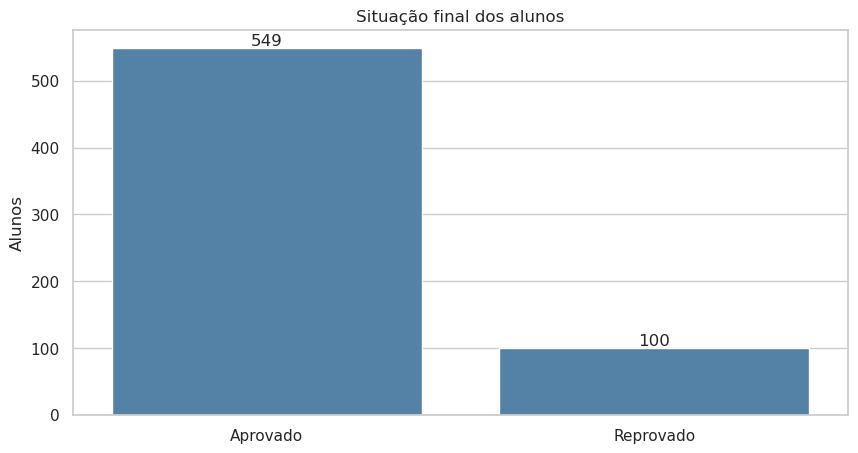

In [21]:
df["Situacao_Final"] = np.where(df["Nota_Final"] >= 10, "Aprovado", "Reprovado")
contagem = df["Situacao_Final"].value_counts()
print(pd.DataFrame({"Alunos": contagem, "%": (contagem / len(df) * 100).round(2)}))

ax = sns.countplot(data=df, x="Situacao_Final", order=["Aprovado", "Reprovado"], color="steelblue")
ax.bar_label(ax.containers[0]); plt.title("Situação final dos alunos"); plt.xlabel(""); plt.ylabel("Alunos")
plt.show()

In [22]:
for coluna in ["Reprovacoes_Anteriores", "Tempo_de_Estudo_Semanal", "Escola", "Acesso_a_Internet_em_Casa"]:
    taxa = pd.crosstab(df[coluna], df["Situacao_Final"], normalize="index").mul(100).round(2)
    if coluna in dicionario_codigos:
        taxa.index = [f"{c} - {dicionario_codigos[coluna][c]}" for c in taxa.index]
    taxa.index.name = coluna
    display(taxa.rename(columns={"Aprovado": "% aprovados", "Reprovado": "% reprovados"}))

sem_zero = df[df["Nota_Final"] > 0]
taxa_sem_zero = sem_zero["Situacao_Final"].eq("Reprovado").groupby(sem_zero["Escola"]).mean().mul(100).round(2)
print("% de reprovados por escola, sem os alunos com nota final 0:", taxa_sem_zero.to_dict())

Situacao_Final,% aprovados,% reprovados
Reprovacoes_Anteriores,,
0 - Nenhuma,90.71,9.29
1 - 1,54.29,45.71
2 - 2,50.00,50.00
3 - 3 ou mais,35.71,64.29


Situacao_Final,% aprovados,% reprovados
Tempo_de_Estudo_Semanal,,
1 - Menos de 2 h,76.42,23.58
2 - 2 a 5 h,86.56,13.44
3 - 5 a 10 h,92.78,7.22
4 - Mais de 10 h,94.29,5.71


Situacao_Final,% aprovados,% reprovados
Escola,,
GP,92.43,7.57
MS,69.91,30.09


Situacao_Final,% aprovados,% reprovados
Acesso_a_Internet_em_Casa,,
Não,78.81,21.19
Sim,86.35,13.65


% de reprovados por escola, sem os alunos com nota final 0: {'GP': 7.35, 'MS': 25.47}


São 549 aprovados (84,59%) e 100 reprovados (15,41%), ou seja, as classes são desbalanceadas. A taxa de reprovação muda bastante entre os grupos:

* 9,29% entre quem nunca reprovou, contra 45,71% a 64,29% entre quem já reprovou;
* 23,58% entre quem estuda menos de 2 h por semana, contra 7,22% e 5,71% nos dois níveis de mais estudo;
* 30,09% na escola MS, contra 7,57% na GP. Dos 15 alunos com nota final zero, 14 são da MS, mas mesmo retirando esses alunos a diferença continua grande (25,47% contra 7,35%);
* 21,19% entre quem não tem internet em casa, contra 13,65% entre quem tem.

O desbalanceamento define duas escolhas da classificação: não vamos julgar os modelos pela acurácia (dizer "aprovado" para todo mundo já dá 84,6%) e vamos testar `class_weight="balanced"`, para que o modelo dê mais peso aos reprovados.

## 2.17 Decisões de codificação e padronização

Com base no que vimos, definimos como cada tipo de variável será transformado. Nada é ajustado aqui: os transformadores são montados num `ColumnTransformer` e aprendem médias, desvios e categorias apenas com os dados de treino, na Etapa 4.

| Tipo de variável | Exemplos | Transformação | Motivo |
|---|---|---|---|
| Binárias de texto | `Sexo`, `Escola`, sim/não | `OneHotEncoder(drop="if_binary")`, vira uma coluna 0/1 | Os modelos só trabalham com números; com duas categorias basta uma coluna |
| Nominais com mais de 2 categorias | `Ocupacao_da_Mae`, `Motivo_da_Escolha_da_Escola` | `OneHotEncoder`, uma coluna 0/1 por categoria | Não existe ordem entre "Saúde" e "Serviços"; transformar em 1, 2, 3 criaria uma ordem falsa |
| Ordinais (códigos) | `Escolaridade_da_Mae`, `Tempo_de_Estudo_Semanal` | Mantidas como número e padronizadas | A ordem tem significado (código 3 estuda mais que código 1) |
| Contínuas / contagens | `Idade`, notas parciais (e `Numero_de_Faltas` no agrupamento) | `StandardScaler` (média 0, desvio 1) | As escalas são muito diferentes (notas de 0 a 20, faltas de 0 a 32, escalas de 1 a 5); isso afeta a regularização e o K-Means |
| Valores ausentes | nenhuma coluna | sem imputação | A base não tem ausentes (seção 2.6) |

Não aplicamos transformação logarítmica nas faltas, porque elas não entram nos modelos de previsão. No agrupamento usamos apenas a padronização, para manter a variável fácil de interpretar.

In [23]:
binarias = [c for c in colunas_categoricas if df[c].nunique() == 2]
nominais = [c for c in colunas_categoricas if df[c].nunique() > 2]
ordinais = list(dicionario_codigos.keys())
continuas = [c for c in colunas_numericas if c not in ordinais]

print("Binárias:", binarias)
print("Nominais:", nominais)
print("Ordinais (códigos):", ordinais)
print("Contínuas / contagens:", continuas)

Binárias: ['Escola', 'Sexo', 'Tipo_de_Endereco', 'Tamanho_da_Familia', 'Situacao_dos_Pais', 'Apoio_Educacional_da_Escola', 'Apoio_Educacional_Familiar', 'Aulas_Particulares_Pagas', 'Atividades_Extracurriculares', 'Frequentou_Educacao_Infantil', 'Pretende_Cursar_Ensino_Superior', 'Acesso_a_Internet_em_Casa', 'Relacionamento_Amoroso']
Nominais: ['Ocupacao_da_Mae', 'Ocupacao_do_Pai', 'Motivo_da_Escolha_da_Escola', 'Responsavel']
Ordinais (códigos): ['Escolaridade_da_Mae', 'Escolaridade_do_Pai', 'Tempo_de_Deslocamento', 'Tempo_de_Estudo_Semanal', 'Reprovacoes_Anteriores', 'Qualidade_das_Relacoes_Familiares', 'Tempo_Livre_Apos_a_Escola', 'Frequencia_de_Saidas_com_Amigos', 'Consumo_de_Alcool_em_Dias_Uteis', 'Consumo_de_Alcool_no_Fim_de_Semana', 'Estado_de_Saude_Atual']
Contínuas / contagens: ['Idade', 'Numero_de_Faltas', 'Nota_1o_Periodo', 'Nota_2o_Periodo', 'Nota_Final']


## 2.18 Resumo da qualidade da base

In [24]:
pd.DataFrame({
    "Indicador": ["Estudantes", "Variáveis originais", "Valores ausentes", "Linhas duplicadas",
                  "Valores fora da escala", "Alunos com nota final 0", "Alunos com mais de 15 faltas",
                  "% de reprovados"],
    "Resultado": [len(df), 33, int(df.isnull().sum().sum()), int(df.duplicated().sum()),
                  int(verificacao["Fora da faixa"].sum()), int((df["Nota_Final"] == 0).sum()),
                  len(atipicos), f'{(df["Situacao_Final"] == "Reprovado").mean() * 100:.2f}%'],
})

,Indicador,Resultado
0,Estudantes,649
1,Variáveis originais,33
2,Valores ausentes,0
3,Linhas duplicadas,0
4,Valores fora da escala,0
5,Alunos com nota final 0,15
6,Alunos com mais de 15 faltas,21
7,% de reprovados,15.41%


### Conclusão da Etapa 2: como a EDA orienta a modelagem

1. Ausentes e duplicados: não existem, então não há imputação nem exclusão de linhas.
2. Notas zero e faltas altas: são casos reais (prováveis abandonos e alunos muito faltosos) e foram mantidos. Esperamos que os zeros aumentem o erro da regressão.
3. Escala e codificação: as variáveis têm escalas muito diferentes e há 17 colunas de texto. Usaremos `StandardScaler` e `OneHotEncoder` dentro de um `Pipeline`, ajustados só no treino.
4. Vazamento temporal: as notas parciais têm correlação de 0,88 e 0,94 com a nota final. Por isso a modelagem é feita em dois cenários: A, sem as notas parciais, e B, com elas. As faltas são o total do ano inteiro e ficam fora dos modelos.
5. Desbalanceamento: 15,41% de reprovados. Na classificação usaremos divisão estratificada, `class_weight="balanced"` e métricas focadas na classe reprovado (recall, precisão e F1).

---

# Etapa 3: Definição da Tarefa

> **Enunciado da Especificação (Etapa 3):** *"3. Definição da tarefa: supervisionada ou não supervisionada; se supervisionada, regressão ou classificação."*

| Tarefa | Tipo | Alvo | Métricas |
|---|---|---|---|
| Prever a nota final | Supervisionada - regressão | `Nota_Final` (0 a 20) | MAE (erro médio em pontos), RMSE e R² |
| Prever reprovação | Supervisionada - classificação binária | `Risco_Reprovacao` (1 = reprovado, 0 = aprovado) | Recall, precisão e F1 da classe 1, matriz de confusão. A acurácia aparece só para comparação, porque com 15% de reprovados um modelo que chuta "aprovado" para todos já acerta 85% |
| Encontrar perfis de alunos | Não supervisionada - agrupamento | não há alvo | Inércia (método do cotovelo) e coeficiente de silhueta; PCA para visualizar |

### 3.1 Variáveis disponíveis em cada cenário

Uma variável só pode entrar no modelo se estiver disponível no momento em que a previsão é feita:

* `Nota_Final`, `Situacao_Final` e `Risco_Reprovacao` são a própria resposta e nunca entram como entrada.
* `Nota_1o_Periodo` e `Nota_2o_Periodo` só existem depois desses períodos, então ficam fora do Cenário A e entram no Cenário B.
* `Numero_de_Faltas` é o total de faltas do ano inteiro, vindo do boletim. No início do ano esse número ainda não existe, e no fim do 2º período ele ainda não está completo, porque inclui faltas do 3º período. A base não traz as faltas acumuladas até o 2º período, então deixamos essa variável fora dos dois cenários. Ela só aparece na EDA e no agrupamento, que são análises descritivas.

In [25]:
df["Risco_Reprovacao"] = (df["Nota_Final"] < 10).astype(int)

colunas_resposta = ["Nota_Final", "Situacao_Final", "Risco_Reprovacao"]
so_no_cenario_b = ["Nota_1o_Periodo", "Nota_2o_Periodo"]
fora_dos_modelos = ["Numero_de_Faltas"]  # total do ano: não estaria disponível em nenhum dos dois momentos

features_a = [c for c in df.columns if c not in colunas_resposta + so_no_cenario_b + fora_dos_modelos]
features_b = features_a + so_no_cenario_b

def separar_tipos(features):
    numericas = [c for c in features if c in colunas_numericas]
    categoricas = [c for c in features if c in colunas_categoricas]
    return numericas, categoricas

cenarios = {
    "A": (features_a, *separar_tipos(features_a)),
    "B": (features_b, *separar_tipos(features_b)),
}
for nome, (feats, num, cat) in cenarios.items():
    print(f"Cenário {nome}: {len(feats)} variáveis ({len(num)} numéricas e {len(cat)} categóricas)")

Cenário A: 29 variáveis (12 numéricas e 17 categóricas)
Cenário B: 31 variáveis (14 numéricas e 17 categóricas)


### 3.2 Divisão treino e teste (antes de qualquer ajuste)

Separamos 80% dos alunos para treino e 20% para teste, com estratificação pelo `Risco_Reprovacao` para manter a mesma proporção de reprovados nos dois conjuntos. Assim, o treino fica com 519 alunos (80 reprovados) e o teste com 130 (20 reprovados), somando os 649 alunos e 100 reprovados da base. Sempre que o notebook fala em 519 alunos, está se referindo ao treino; quando fala em 130, ao teste. A mesma divisão é usada na regressão e na classificação. O conjunto de teste fica guardado e só é usado uma vez, na Etapa 5.

In [26]:
idx_treino, idx_teste = train_test_split(df.index, test_size=0.20, random_state=SEMENTE,
                                         stratify=df["Risco_Reprovacao"])

divisao = pd.DataFrame({
    "Alunos": [len(idx_treino), len(idx_teste)],
    "Reprovados": [df.loc[idx_treino, "Risco_Reprovacao"].sum(), df.loc[idx_teste, "Risco_Reprovacao"].sum()],
    "% reprovados": [round(df.loc[idx_treino, "Risco_Reprovacao"].mean() * 100, 2),
                     round(df.loc[idx_teste, "Risco_Reprovacao"].mean() * 100, 2)],
}, index=["Treino", "Teste"])
divisao

,Alunos,Reprovados,% reprovados
Treino,519,80,15.41
Teste,130,20,15.38


---

# Etapa 4: Construção do Modelo

> **Enunciado da Especificação (Etapa 4):** *"4. Construção do modelo: algoritmos adequados ao problema, sempre comparados com uma referência simples (por exemplo, prever a média ou a classe mais comum)."*

Todos os modelos supervisionados são montados como `Pipeline(pré-processamento + modelo)`. Assim, o `StandardScaler` e o `OneHotEncoder` são ajustados de novo em cada rodada, só com os dados de treino daquela rodada.

Para escolher hiperparâmetros (força da regularização, profundidade das árvores) e comparar os modelos, usamos validação cruzada com 5 partes dentro do conjunto de treino (`GridSearchCV`). O teste não participa de nenhuma escolha.

Usamos dois tipos de referência simples:

* Referência ingênua (`Dummy`): prevê sempre a média ou a classe mais comum. Mostra o mínimo que qualquer modelo precisa superar.
* Referência por regra, que é o que a escola faria sem Machine Learning. No Cenário A, a regra é "quem já reprovou antes está em risco". No Cenário B, as regras são "quem tirou menos de 10 no 2º período está em risco" e "a nota final será igual à do 2º período". Essas regras não aprendem nada dos dados, então não há risco de vazamento. Se um modelo não supera a regra, ele não justifica a complexidade.

In [27]:
def criar_preprocessador(numericas, categoricas):
    return ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categoricas),
    ])

class RegraNota2(BaseEstimator, RegressorMixin):
    # referência: a nota final prevista é a própria nota do 2º período
    def fit(self, X, y):
        self.n_features_in_ = X.shape[1]  # não aprende nada; só marca como ajustado
        return self
    def predict(self, X):
        return X["Nota_2o_Periodo"].to_numpy(dtype=float)

class RegraRisco(BaseEstimator, ClassifierMixin):
    # referência: marca risco (1) quando a coluna indicada passa do limite
    def __init__(self, coluna="Nota_2o_Periodo", limite=10, abaixo=True):
        self.coluna, self.limite, self.abaixo = coluna, limite, abaixo
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        return self
    def predict(self, X):
        valores = X[self.coluna]
        return (valores < self.limite if self.abaixo else valores > self.limite).astype(int).to_numpy()

def montar(modelo, numericas, categoricas):
    # as regras usam a coluna original, sem padronização
    if isinstance(modelo, (RegraNota2, RegraRisco)):
        return Pipeline([("modelo", modelo)])
    return Pipeline([("prep", criar_preprocessador(numericas, categoricas)), ("modelo", modelo)])

def eh_referencia(nome):
    return nome.startswith("Referência")

def nome_parametros(params):
    return ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in params.items()) or "-"

def dados(cenario, alvo):
    feats = cenarios[cenario][0]
    return (df.loc[idx_treino, feats], df.loc[idx_teste, feats],
            df.loc[idx_treino, alvo], df.loc[idx_teste, alvo])

## 4.1 Regressão - `Nota_Final`

* Referências: `DummyRegressor`, que prevê sempre a nota média do treino, e, no Cenário B, a regra "nota final = nota do 2º período".
* Regressão Linear: modelo linear sem regularização.
* Ridge: regressão linear com regularização L2 (encolhe os coeficientes).
* Lasso: regressão linear com regularização L1 (pode zerar coeficientes de variáveis fracas).
* Random Forest: conjunto de árvores; limitamos a profundidade e o tamanho mínimo das folhas para não decorar o treino.

In [28]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)

def modelos_regressao(cenario):
    referencias = {"Referência (média)": (DummyRegressor(strategy="mean"), {})}
    if cenario == "B":
        referencias["Referência (regra: nota final = nota do 2º período)"] = (RegraNota2(), {})
    return {
        **referencias,
        "Regressão Linear": (LinearRegression(), {}),
        "Ridge (L2)": (Ridge(), {"modelo__alpha": [0.1, 1, 10, 30, 100, 300, 1000]}),
        "Lasso (L1)": (Lasso(max_iter=20000), {"modelo__alpha": [0.003, 0.01, 0.03, 0.1, 0.3, 1]}),
        "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=SEMENTE, n_jobs=-1),
                          {"modelo__max_depth": [3, 5, 8, 12, None], "modelo__min_samples_leaf": [1, 5, 10]}),
    }

def construir_regressao(cenario):
    X_tr, _, y_tr, _ = dados(cenario, "Nota_Final")
    _, num, cat = cenarios[cenario]
    linhas, ajustados = [], {}
    for nome, (modelo, grade) in modelos_regressao(cenario).items():
        pipe = montar(modelo, num, cat)
        busca = GridSearchCV(pipe, grade, cv=cv_reg, scoring="neg_mean_absolute_error",
                             return_train_score=True)
        busca.fit(X_tr, y_tr)
        i = busca.best_index_
        linhas.append({
            "Modelo": nome,
            "Hiperparâmetros escolhidos": nome_parametros(busca.best_params_),
            "MAE treino (CV)": -busca.cv_results_["mean_train_score"][i],
            "MAE validação (CV)": -busca.cv_results_["mean_test_score"][i],
            "Desvio entre partes": busca.cv_results_["std_test_score"][i],
        })
        ajustados[nome] = busca.best_estimator_
    return pd.DataFrame(linhas).round(3), ajustados

cv_reg_a, modelos_reg_a = construir_regressao("A")
cv_reg_b, modelos_reg_b = construir_regressao("B")

print("Cenário A - início do ano (validação cruzada no treino)")
display(cv_reg_a)
print("Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)")
display(cv_reg_b)

def melhor(tabela, coluna, menor_melhor):
    candidatos = tabela[~tabela["Modelo"].map(eh_referencia)]
    return candidatos.sort_values(coluna, ascending=menor_melhor).iloc[0]["Modelo"]

escolhido_reg_a = melhor(cv_reg_a, "MAE validação (CV)", True)
escolhido_reg_b = melhor(cv_reg_b, "MAE validação (CV)", True)
print(f"Escolhido pela validação: Cenário A = {escolhido_reg_a} | Cenário B = {escolhido_reg_b}")

Cenário A - início do ano (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,MAE treino (CV),MAE validação (CV),Desvio entre partes
0,Referência (média),-,2.355,2.364,0.189
1,Regressão Linear,-,1.813,1.970,0.088
2,Ridge (L2),alpha=30,1.812,1.925,0.101
3,Lasso (L1),alpha=0.03,1.819,1.933,0.093
4,Random Forest,"max_depth=12, min_samples_leaf=5",1.330,1.914,0.097


Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,MAE treino (CV),MAE validação (CV),Desvio entre partes
0,Referência (média),-,2.355,2.364,0.189
1,Referência (regra: nota final = nota do 2º per...,-,0.771,0.771,0.062
2,Regressão Linear,-,0.758,0.841,0.102
3,Ridge (L2),alpha=30,0.751,0.806,0.070
4,Lasso (L1),alpha=0.3,0.765,0.767,0.068
5,Random Forest,"max_depth=5, min_samples_leaf=1",0.568,0.784,0.079


Escolhido pela validação: Cenário A = Random Forest | Cenário B = Lasso (L1)


Na validação cruzada:

* Cenário A: a referência erra em média 2,36 pontos. Os modelos ficam entre 1,91 e 1,97 pontos, muito próximos entre si: a diferença entre eles (cerca de 0,06 ponto) é menor que a variação entre as partes da validação (cerca de 0,1). O Random Forest teve o menor erro de validação, mas também a maior distância entre treino (1,33) e validação (1,91), sinal de que ele aprende detalhes do treino que não se repetem em alunos novos.
* Cenário B: a regra "nota final = nota do 2º período" erra em média 0,77 ponto, sem treinar nada. O melhor modelo, o Lasso (`alpha=0,3`), também erra 0,77. Ou seja, no Cenário B os modelos empatam com a regra; a regressão linear sem regularização (0,84) e a Ridge (0,81) ficam até piores que ela.

Os valores testados para cada hiperparâmetro foram escolhidos para que o melhor valor não ficasse no limite da grade. O modelo de cada cenário foi escolhido aqui, pela validação, e não pelo resultado no teste.

## 4.2 Classificação - `Risco_Reprovacao`

* Referências: `DummyClassifier`, que prevê sempre a classe mais comum (aprovado), e as regras "já reprovou antes" (Cenário A) e "nota do 2º período < 10" (Cenário B).
* Regressão Logística sem balanceamento: para mostrar o efeito do desbalanceamento.
* Regressão Logística balanceada: `class_weight="balanced"` dá mais peso aos reprovados; a força da regularização L2 (`C`) é escolhida na validação.
* Random Forest balanceado: também com `class_weight="balanced"` e profundidade limitada.

Na validação cruzada usamos partes estratificadas e escolhemos os hiperparâmetros pelo F1 da classe reprovado, que equilibra encontrar reprovados (recall) e não gerar alarmes demais (precisão).

In [29]:
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
# zero_division=0: quando um modelo não aponta nenhum reprovado (o Dummy), a precisão vale 0 em vez de gerar aviso
metricas_cv = {"f1": make_scorer(f1_score, zero_division=0), "recall": "recall",
               "precisao": make_scorer(precision_score, zero_division=0)}

def modelos_classificacao(cenario):
    if cenario == "A":
        regra = ("Referência (regra: já reprovou antes)", RegraRisco("Reprovacoes_Anteriores", 0, abaixo=False))
    else:
        regra = ("Referência (regra: nota do 2º período < 10)", RegraRisco("Nota_2o_Periodo", 10, abaixo=True))
    return {
        "Referência (classe mais comum)": (DummyClassifier(strategy="most_frequent"), {}),
        regra[0]: (regra[1], {}),
        "Logística sem balanceamento": (LogisticRegression(max_iter=2000), {}),
        "Logística balanceada (L2)": (LogisticRegression(class_weight="balanced", max_iter=2000),
                                      {"modelo__C": [0.0001, 0.001, 0.003, 0.01, 0.05, 0.1, 0.5, 1, 10]}),
        "Random Forest balanceado": (RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                            random_state=SEMENTE, n_jobs=-1),
                                     {"modelo__max_depth": [1, 2, 3, 5, 8, 12, None], "modelo__min_samples_leaf": [1, 5, 10]}),
    }

def construir_classificacao(cenario):
    X_tr, _, y_tr, _ = dados(cenario, "Risco_Reprovacao")
    _, num, cat = cenarios[cenario]
    linhas, ajustados = [], {}
    for nome, (modelo, grade) in modelos_classificacao(cenario).items():
        pipe = montar(modelo, num, cat)
        busca = GridSearchCV(pipe, grade, cv=cv_clf, scoring=metricas_cv, refit="f1",
                             return_train_score=True, error_score="raise")
        busca.fit(X_tr, y_tr)
        i, r = busca.best_index_, busca.cv_results_
        linhas.append({
            "Modelo": nome,
            "Hiperparâmetros escolhidos": nome_parametros(busca.best_params_),
            "Recall validação (CV)": r["mean_test_recall"][i],
            "Precisão validação (CV)": r["mean_test_precisao"][i],
            "F1 treino (CV)": r["mean_train_f1"][i],
            "F1 validação (CV)": r["mean_test_f1"][i],
            "F1 em cada parte (CV)": " / ".join(f"{r[f'split{k}_test_f1'][i]:.2f}" for k in range(5)),
        })
        ajustados[nome] = busca.best_estimator_
    return pd.DataFrame(linhas).round(3), ajustados

cv_clf_a, modelos_clf_a = construir_classificacao("A")
cv_clf_b, modelos_clf_b = construir_classificacao("B")

print("Cenário A - início do ano (validação cruzada no treino)")
display(cv_clf_a)
print("Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)")
display(cv_clf_b)

escolhido_clf_a = melhor(cv_clf_a, "F1 validação (CV)", False)
escolhido_clf_b = melhor(cv_clf_b, "F1 validação (CV)", False)
print(f"Escolhido pela validação: Cenário A = {escolhido_clf_a} | Cenário B = {escolhido_clf_b}")

Cenário A - início do ano (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,Recall validação (CV),Precisão validação (CV),F1 treino (CV),F1 validação (CV),F1 em cada parte (CV)
0,Referência (classe mais comum),-,0.000,0.000,0.000,0.000,0.00 / 0.00 / 0.00 / 0.00 / 0.00
1,Referência (regra: já reprovou antes),-,0.525,0.510,0.512,0.514,0.56 / 0.56 / 0.23 / 0.67 / 0.55
2,Logística sem balanceamento,-,0.312,0.564,0.522,0.394,0.29 / 0.67 / 0.28 / 0.48 / 0.26
3,Logística balanceada (L2),C=0.001,0.638,0.412,0.519,0.497,0.46 / 0.54 / 0.36 / 0.64 / 0.49
4,Random Forest balanceado,"max_depth=2, min_samples_leaf=10",0.738,0.406,0.566,0.522,0.48 / 0.57 / 0.44 / 0.58 / 0.54


Cenário B - com notas do 1º e 2º períodos (validação cruzada no treino)


,Modelo,Hiperparâmetros escolhidos,Recall validação (CV),Precisão validação (CV),F1 treino (CV),F1 validação (CV),F1 em cada parte (CV)
0,Referência (classe mais comum),-,0.000,0.000,0.000,0.000,0.00 / 0.00 / 0.00 / 0.00 / 0.00
1,Referência (regra: nota do 2º período < 10),-,0.888,0.624,0.725,0.730,0.68 / 0.76 / 0.57 / 0.86 / 0.78
2,Logística sem balanceamento,-,0.662,0.762,0.862,0.701,0.69 / 0.54 / 0.69 / 0.71 / 0.88
3,Logística balanceada (L2),C=0.1,0.938,0.624,0.792,0.745,0.70 / 0.79 / 0.53 / 0.86 / 0.84
4,Random Forest balanceado,"max_depth=12, min_samples_leaf=1",0.838,0.758,0.997,0.791,0.76 / 0.73 / 0.67 / 0.88 / 0.91


Escolhido pela validação: Cenário A = Random Forest balanceado | Cenário B = Random Forest balanceado


* A referência ingênua tem recall zero: ela nunca aponta um reprovado.
* Cenário A: a regra "já reprovou antes" tem F1 de validação 0,51. O Random Forest balanceado foi o melhor modelo (0,52), praticamente empatado com a regra no F1, mas com outro perfil: encontra 74% dos reprovados (a regra encontra 53%) e erra mais nos alarmes (precisão de 41% contra 51%). A Logística balanceada (0,50) ficou abaixo da regra, e a Logística sem balanceamento (0,39) bem abaixo, porque aprende que dizer "aprovado" quase sempre é o caminho mais seguro.
* No Cenário A, a validação preferiu árvores bem rasas (profundidade 2) e uma Logística com regularização muito forte (`C=0,001`). As duas coisas indicam que o sinal disponível no início do ano é fraco e que, com só 80 reprovados no treino, modelos simples generalizam melhor.
* Cenário B: a regra "nota do 2º período < 10" tem F1 de validação 0,73. O Random Forest balanceado foi o melhor (0,79) e superou a regra em 4 das 5 partes da validação, mas com diferença pequena e com F1 de treino praticamente 1,0, sinal de sobreajuste. O teste vai mostrar se essa vantagem se mantém.

## 4.3 Agrupamento - K-Means com PCA

Usamos as 13 variáveis numéricas de família, rotina e comportamento, sem as notas. Como não existe alvo, não há risco de vazamento da resposta, e o agrupamento é usado de forma descritiva sobre todos os alunos. As variáveis são padronizadas porque o K-Means usa distância, e sem isso as faltas (0 a 32) dominariam as escalas de 1 a 5.

Para escolher o número de grupos (k), testamos de 2 a 8 e olhamos a inércia (método do cotovelo) e o coeficiente de silhueta (vai de -1 a 1; quanto maior, mais separados estão os grupos).

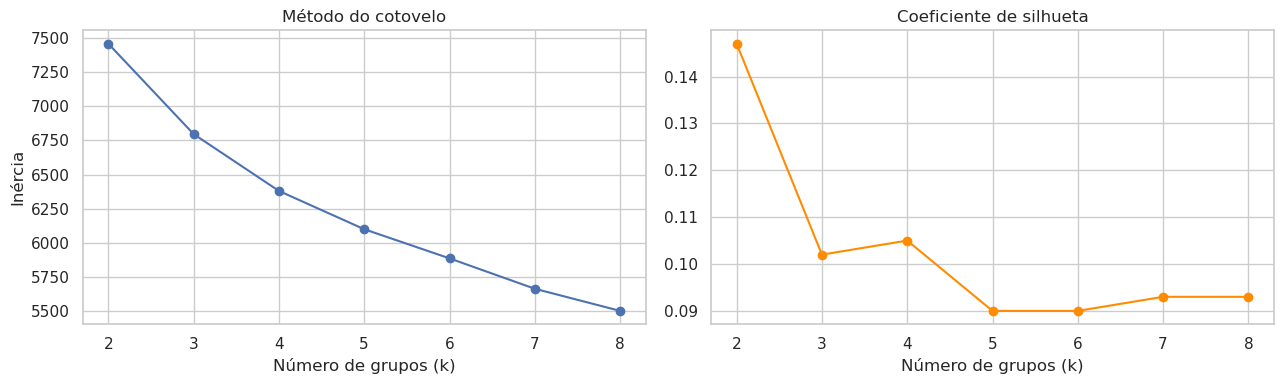

,k,Inércia,Silhueta
0,2,7457.7,0.147
1,3,6795.9,0.102
2,4,6379.6,0.105
3,5,6099.4,0.090
4,6,5886.0,0.090
5,7,5663.5,0.093
6,8,5501.5,0.093


In [30]:
colunas_cluster = ["Idade", "Escolaridade_da_Mae", "Escolaridade_do_Pai", "Tempo_de_Deslocamento",
                   "Tempo_de_Estudo_Semanal", "Reprovacoes_Anteriores", "Qualidade_das_Relacoes_Familiares",
                   "Tempo_Livre_Apos_a_Escola", "Frequencia_de_Saidas_com_Amigos",
                   "Consumo_de_Alcool_em_Dias_Uteis", "Consumo_de_Alcool_no_Fim_de_Semana",
                   "Estado_de_Saude_Atual", "Numero_de_Faltas"]

X_cluster = StandardScaler().fit_transform(df[colunas_cluster])

avaliacao_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10).fit(X_cluster)
    avaliacao_k.append({"k": k, "Inércia": round(km.inertia_, 1),
                        "Silhueta": round(silhouette_score(X_cluster, km.labels_), 3)})
avaliacao_k = pd.DataFrame(avaliacao_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(avaliacao_k["k"], avaliacao_k["Inércia"], marker="o"); axes[0].set_title("Método do cotovelo")
axes[0].set_xlabel("Número de grupos (k)"); axes[0].set_ylabel("Inércia")
axes[1].plot(avaliacao_k["k"], avaliacao_k["Silhueta"], marker="o", color="darkorange")
axes[1].set_title("Coeficiente de silhueta"); axes[1].set_xlabel("Número de grupos (k)")
plt.tight_layout(); plt.show()
avaliacao_k

A inércia cai de forma gradual, sem um "cotovelo" bem marcado, e a silhueta é baixa para qualquer k (no máximo 0,147, com k=2). Isso quer dizer que os alunos não formam grupos naturalmente separados: os perfis se sobrepõem.

Escolhemos k = 3. Com k=2 a silhueta é um pouco maior, mas dois grupos dizem pouco para a coordenação. A partir de k=3 a silhueta fica praticamente estável (0,09 a 0,10), então não há ganho em criar mais grupos, e três perfis são fáceis de descrever e de usar. Tratamos os grupos como um resumo de perfis, não como categorias exatas.

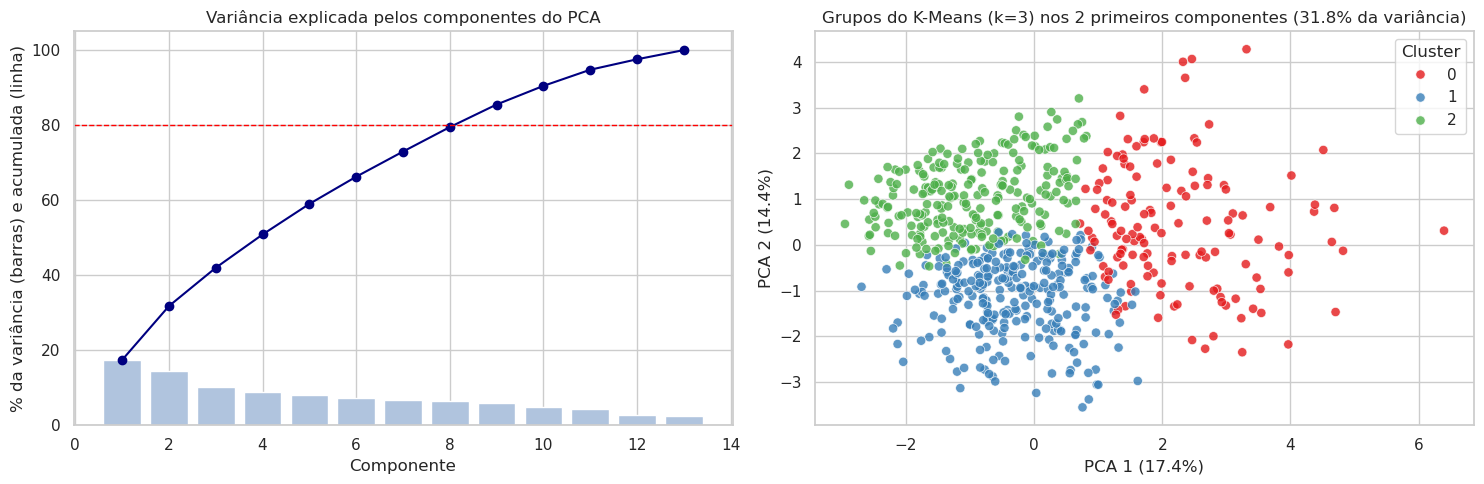

Componentes necessários para explicar 80% da variância: 9 de 13


In [31]:
K_ESCOLHIDO = 3
kmeans = KMeans(n_clusters=K_ESCOLHIDO, random_state=SEMENTE, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_cluster)

pca_completo = PCA(random_state=SEMENTE).fit(X_cluster)
variancia_acumulada = np.cumsum(pca_completo.explained_variance_ratio_) * 100

pca = PCA(n_components=2, random_state=SEMENTE)
coords = pca.fit_transform(X_cluster)
df["PCA1"], df["PCA2"] = coords[:, 0], coords[:, 1]
var = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(range(1, len(variancia_acumulada) + 1), pca_completo.explained_variance_ratio_ * 100, color="lightsteelblue")
axes[0].plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker="o", color="navy")
axes[0].axhline(80, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Variância explicada pelos componentes do PCA")
axes[0].set_xlabel("Componente"); axes[0].set_ylabel("% da variância (barras) e acumulada (linha)")
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Cluster", palette="Set1", s=45, alpha=0.8, ax=axes[1])
axes[1].set_title(f"Grupos do K-Means (k={K_ESCOLHIDO}) nos 2 primeiros componentes ({var.sum():.1f}% da variância)")
axes[1].set_xlabel(f"PCA 1 ({var[0]:.1f}%)"); axes[1].set_ylabel(f"PCA 2 ({var[1]:.1f}%)")
plt.tight_layout(); plt.show()

print(f"Componentes necessários para explicar 80% da variância: {np.argmax(variancia_acumulada >= 80) + 1} de {len(colunas_cluster)}")

Os dois primeiros componentes explicam só 31,8% da variância (17,4% + 14,4%), e são necessários 9 dos 13 componentes para chegar a 80%. As variáveis trazem informações bem diferentes entre si, e o gráfico em 2D é uma simplificação; por isso os grupos aparecem com sobreposição, o que combina com a silhueta baixa.

Usamos o PCA para visualizar os grupos, e não para reduzir as variáveis dos modelos supervisionados. Com 29 a 31 variáveis e regularização, não há necessidade de comprimir os dados, e os componentes tornariam os resultados difíceis de explicar para a escola.

---

# Etapa 5: Avaliação

> **Enunciado da Especificação (Etapa 5):** *"5. Avaliação: métricas apropriadas ao problema, lidas na unidade do negócio ("erramos em média 2,5 anos", "encontramos 70% dos clientes que cancelam")."*

Agora cada modelo, já com os hiperparâmetros escolhidos na validação e treinado em todo o conjunto de treino, é aplicado uma única vez nos 130 alunos do teste.

## 5.1 Regressão - erro em pontos de nota

In [32]:
def avaliar_regressao(modelos, cenario):
    X_tr, X_te, y_tr, y_te = dados(cenario, "Nota_Final")
    linhas = []
    for nome, pipe in modelos.items():
        p_tr, p_te = pipe.predict(X_tr), pipe.predict(X_te)
        linhas.append({
            "Cenário": cenario, "Modelo": nome,
            "MAE treino": mean_absolute_error(y_tr, p_tr), "MAE teste": mean_absolute_error(y_te, p_te),
            "RMSE teste": np.sqrt(mean_squared_error(y_te, p_te)),
            "R² treino": r2_score(y_tr, p_tr), "R² teste": r2_score(y_te, p_te),
        })
    resultado = pd.DataFrame(linhas)
    numericas = resultado.select_dtypes("number").columns
    resultado[numericas] = resultado[numericas].round(3) + 0.0  # evita exibir "-0.000"
    return resultado

teste_reg = pd.concat([avaliar_regressao(modelos_reg_a, "A"), avaliar_regressao(modelos_reg_b, "B")], ignore_index=True)
teste_reg[["Cenário", "Modelo", "MAE teste", "RMSE teste", "R² teste"]]

,Cenário,Modelo,MAE teste,RMSE teste,R² teste
0,A,Referência (média),2.600,3.562,0.000
1,A,Regressão Linear,2.226,3.104,0.240
2,A,Ridge (L2),2.215,3.098,0.243
3,A,Lasso (L1),2.242,3.120,0.233
4,A,Random Forest,2.221,3.109,0.238
5,B,Referência (média),2.600,3.562,0.000
6,B,Referência (regra: nota final = nota do 2º per...,0.754,1.425,0.840
7,B,Regressão Linear,0.850,1.470,0.830
8,B,Ridge (L2),0.852,1.495,0.824
9,B,Lasso (L1),0.825,1.470,0.830


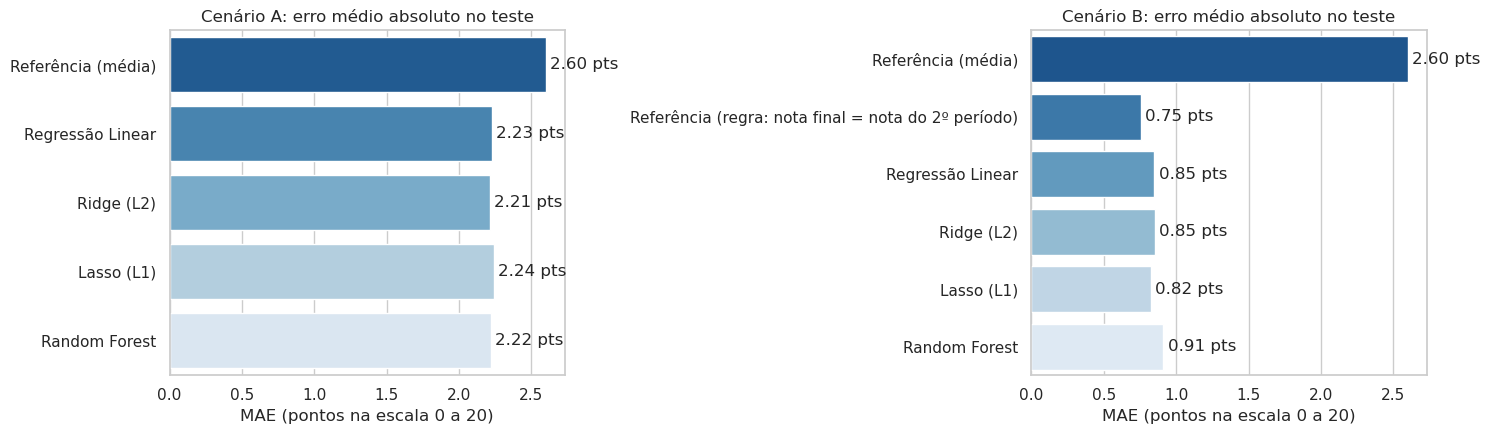

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
for ax, cen in zip(axes, ["A", "B"]):
    parte = teste_reg[teste_reg["Cenário"] == cen]
    sns.barplot(data=parte, x="MAE teste", y="Modelo", hue="Modelo", palette="Blues_r", legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f pts", padding=3)
    ax.set_title(f"Cenário {cen}: erro médio absoluto no teste"); ax.set_xlabel("MAE (pontos na escala 0 a 20)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

O MAE médio esconde onde o modelo erra mais. Abaixo, o erro do modelo escolhido em cada cenário separado por faixa da nota real.

In [34]:
faixas_nota = pd.cut(df.loc[idx_teste, "Nota_Final"], bins=[-1, 0, 9, 13, 20],
                     labels=["Nota 0", "1 a 9 (reprovado)", "10 a 13", "14 a 20"])

erros = {}
for cen, modelos, escolhido in [("A", modelos_reg_a, escolhido_reg_a), ("B", modelos_reg_b, escolhido_reg_b)]:
    _, X_te, _, y_te = dados(cen, "Nota_Final")
    erros[f"Cenário {cen} - {escolhido} (MAE)"] = (y_te - modelos[escolhido].predict(X_te)).abs()
_, X_te, _, y_te = dados("B", "Nota_Final")
erros["Cenário B - regra nota do 2º período (MAE)"] = (y_te - X_te["Nota_2o_Periodo"]).abs()

tabela_faixas = pd.DataFrame(erros).groupby(faixas_nota, observed=True).mean().round(2)
tabela_faixas.insert(0, "Alunos no teste", faixas_nota.value_counts().reindex(tabela_faixas.index))
tabela_faixas

,Alunos no teste,Cenário A - Random Forest (MAE),Cenário B - Lasso (L1) (MAE),Cenário B - regra nota do 2º período (MAE)
Nota_Final,,,,
Nota 0,4,10.58,4.44,3.00
1 a 9 (reprovado),16,2.75,1.29,1.19
10 a 13,68,1.42,0.59,0.57
14 a 20,42,2.53,0.69,0.67


Leitura na unidade do problema (pontos na escala de 0 a 20):

* Referência ingênua: prever a nota média do treino para todo mundo erra, em média, 2,60 pontos no teste.
* Cenário A (início do ano): o Random Forest, escolhido na validação, erra em média 2,22 pontos (R² = 0,24). Os outros modelos ficam entre 2,22 e 2,24. Ganhamos cerca de 0,38 ponto por aluno em relação à referência, uma melhora de 15%. É uma previsão grosseira: um aluno previsto com 11 pode terminar com 9 ou com 13.
* Cenário B (fim do 2º período): o Lasso erra em média 0,82 ponto (R² = 0,83). A regra "nota final = nota do 2º período" erra 0,75 ponto (R² = 0,84), ou seja, um pouco menos que qualquer modelo. Para prever a nota nesse momento, o Machine Learning não acrescenta nada à própria nota do 2º período.

A tabela por faixa mostra onde estão os erros. No Cenário A, o erro é de 1,42 ponto para alunos com nota entre 10 e 13, mas sobe para 2,75 nos reprovados com nota de 1 a 9 e para 10,58 nos 4 alunos com nota zero. O modelo puxa as previsões para o meio da escala e não tem como antecipar quem vai abandonar. No Cenário B, tanto o Lasso quanto a regra erram mais nos alunos com nota zero (4,44 e 3,00 pontos).

## 5.2 Classificação - quantos reprovados encontramos

In [35]:
def avaliar_classificacao(modelos, cenario):
    X_tr, X_te, y_tr, y_te = dados(cenario, "Risco_Reprovacao")
    linhas = []
    for nome, pipe in modelos.items():
        p_tr, p_te = pipe.predict(X_tr), pipe.predict(X_te)
        tn, fp, fn, tp = confusion_matrix(y_te, p_te).ravel()
        linhas.append({
            "Cenário": cenario, "Modelo": nome,
            "Reprovados encontrados": f"{tp} de {tp + fn}", "Falsos alarmes": fp,
            "Recall teste (%)": recall_score(y_te, p_te, zero_division=0) * 100,
            "Precisão teste (%)": precision_score(y_te, p_te, zero_division=0) * 100,
            "F1 treino": f1_score(y_tr, p_tr, zero_division=0), "F1 teste": f1_score(y_te, p_te, zero_division=0),
            "Recall treino (%)": recall_score(y_tr, p_tr, zero_division=0) * 100,
            "Acurácia teste (%)": accuracy_score(y_te, p_te) * 100,
        })
    return pd.DataFrame(linhas).round(3)

teste_clf = pd.concat([avaliar_classificacao(modelos_clf_a, "A"), avaliar_classificacao(modelos_clf_b, "B")], ignore_index=True)
teste_clf[["Cenário", "Modelo", "Reprovados encontrados", "Falsos alarmes", "Recall teste (%)",
           "Precisão teste (%)", "F1 teste", "Acurácia teste (%)"]].round(
    {"Recall teste (%)": 1, "Precisão teste (%)": 1, "F1 teste": 3, "Acurácia teste (%)": 1})

,Cenário,Modelo,Reprovados encontrados,Falsos alarmes,Recall teste (%),Precisão teste (%),F1 teste,Acurácia teste (%)
0,A,Referência (classe mais comum),0 de 20,0,0.0,0.0,0.000,84.6
1,A,Referência (regra: já reprovou antes),7 de 20,9,35.0,43.8,0.389,83.1
2,A,Logística sem balanceamento,2 de 20,4,10.0,33.3,0.154,83.1
3,A,Logística balanceada (L2),11 de 20,21,55.0,34.4,0.423,76.9
4,A,Random Forest balanceado,14 de 20,19,70.0,42.4,0.528,80.8
5,B,Referência (classe mais comum),0 de 20,0,0.0,0.0,0.000,84.6
6,B,Referência (regra: nota do 2º período < 10),18 de 20,11,90.0,62.1,0.735,90.0
7,B,Logística sem balanceamento,16 de 20,6,80.0,72.7,0.762,92.3
8,B,Logística balanceada (L2),18 de 20,13,90.0,58.1,0.706,88.5
9,B,Random Forest balanceado,17 de 20,12,85.0,58.6,0.694,88.5


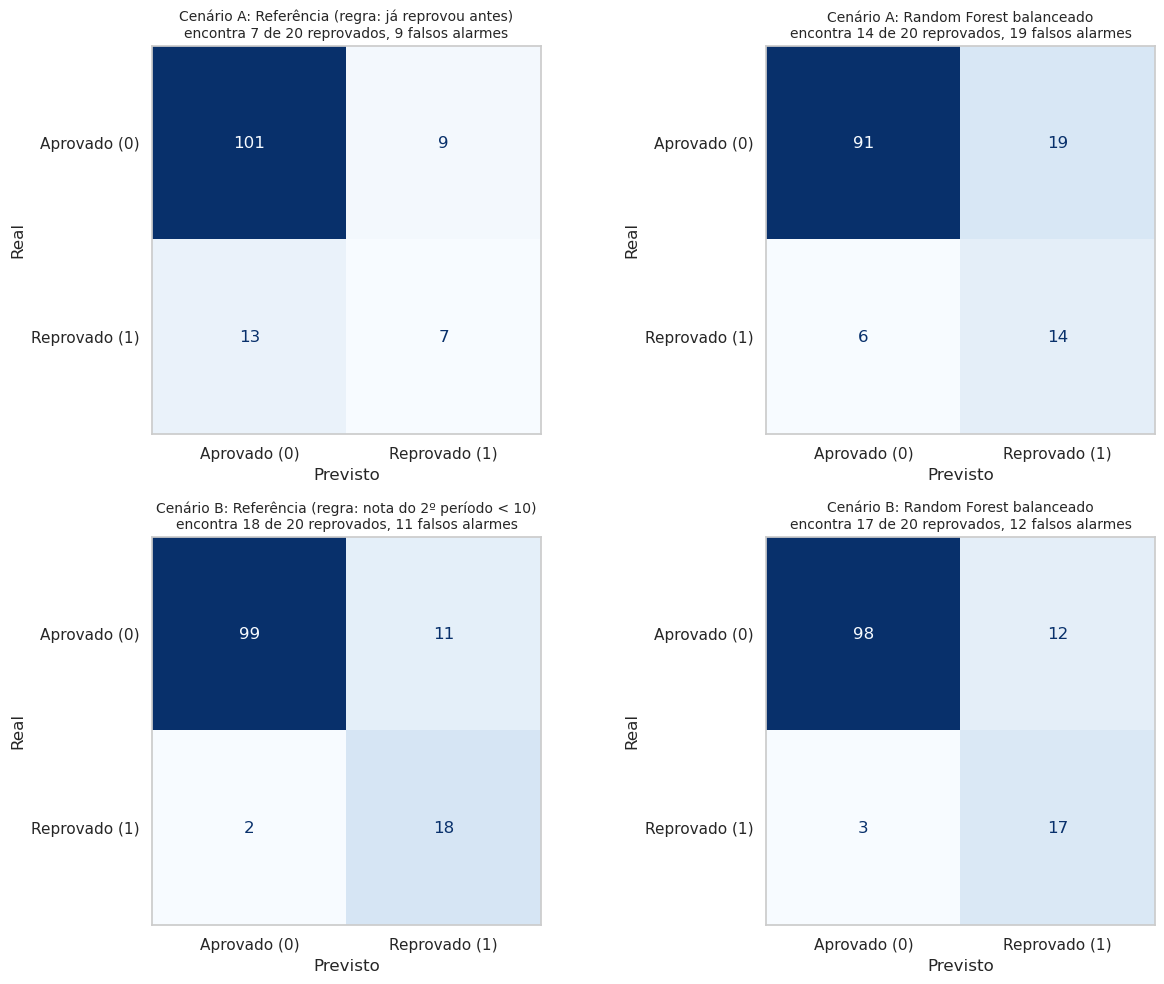

In [36]:
comparacoes = [("A", modelos_clf_a, "Referência (regra: já reprovou antes)"),
               ("A", modelos_clf_a, escolhido_clf_a),
               ("B", modelos_clf_b, "Referência (regra: nota do 2º período < 10)"),
               ("B", modelos_clf_b, escolhido_clf_b)]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()
for ax, (cen, modelos, nome) in zip(axes, comparacoes):
    _, X_te, _, y_te = dados(cen, "Risco_Reprovacao")
    cm = confusion_matrix(y_te, modelos[nome].predict(X_te))
    ConfusionMatrixDisplay(cm, display_labels=["Aprovado (0)", "Reprovado (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Cenário {cen}: {nome}\nencontra {cm[1, 1]} de {cm[1].sum()} reprovados, {cm[0, 1]} falsos alarmes", fontsize=10)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.grid(False)
plt.tight_layout(); plt.show()

No teste há 130 alunos, sendo 20 reprovados.

* Referência ingênua: 84,6% de acurácia, mas encontra 0 dos 20 reprovados. É o exemplo de por que a acurácia sozinha engana aqui.
* Cenário A, regra "já reprovou antes": indica 16 alunos e encontra 7 dos 20 reprovados (35%), com 9 falsos alarmes.
* Cenário A, modelo escolhido (Random Forest balanceado): indica 33 alunos e encontra 70% dos que iam reprovar (14 de 20) ainda no início do ano, com 19 falsos alarmes. A precisão é de 42%: de cada 100 alunos indicados, cerca de 42 reprovariam. A Logística balanceada encontrou 11 de 20 (21 falsos alarmes) e a sem balanceamento só 2 de 20. Como o modelo indica o dobro de alunos da regra, essa comparação ainda não é justa; ela é refeita logo abaixo.
* Cenário B: a regra "nota do 2º período < 10" encontra 18 de 20 reprovados, com 11 falsos alarmes (F1 = 0,735). O Random Forest escolhido encontra 17 de 20, com 12 falsos alarmes (F1 = 0,694). A pequena vantagem que ele teve na validação não apareceu no teste. A recomendação não vem do resultado do teste: os dois caminhos têm desempenho parecido, e nesse caso preferimos a regra, que qualquer professor entende e aplica sem modelo.

Para a escola, um falso alarme custa uma vaga de reforço para um aluno que passaria de qualquer forma; perder um reprovado significa não ajudar quem precisava. Por isso priorizamos o recall e aceitamos uma precisão menor.

No Cenário A, o modelo encontrou o dobro de reprovados da regra "já reprovou antes", mas também indicou o dobro de alunos. Para entender essa diferença, primeiro separamos os reprovados do teste entre quem já tinha reprovado e quem nunca tinha reprovado.

In [37]:
_, X_te, _, y_te = dados("A", "Risco_Reprovacao")
reprovou = (y_te == 1).to_numpy()
ja_reprovou = (X_te["Reprovacoes_Anteriores"] > 0).to_numpy()
achou_regra = modelos_clf_a["Referência (regra: já reprovou antes)"].predict(X_te) == 1
achou_modelo = modelos_clf_a[escolhido_clf_a].predict(X_te) == 1

grupos = {"Já tinham reprovado antes": ja_reprovou, "Nunca tinham reprovado": ~ja_reprovou}
tabela = pd.DataFrame({
    "Reprovados no teste": [(reprovou & g).sum() for g in grupos.values()],
    "Encontrados pela regra": [(achou_regra & reprovou & g).sum() for g in grupos.values()],
    f"Encontrados pelo {escolhido_clf_a}": [(achou_modelo & reprovou & g).sum() for g in grupos.values()],
}, index=grupos.keys())
print(f"Alunos indicados para apoio: regra = {achou_regra.sum()} | modelo = {achou_modelo.sum()}")
tabela

Alunos indicados para apoio: regra = 16 | modelo = 33


,Reprovados no teste,Encontrados pela regra,Encontrados pelo Random Forest balanceado
Já tinham reprovado antes,7,7,6
Nunca tinham reprovado,13,0,8


Uma comparação justa precisa que os dois indiquem o mesmo número de alunos. O modelo dá a cada aluno uma probabilidade de reprovar; ordenamos os alunos por essa probabilidade e pegamos a mesma quantidade que a regra indica. Fazemos isso no treino, com probabilidades da validação cruzada (cada aluno é previsto por um modelo que não o viu no ajuste), e no teste. Também comparamos com uma regra de duas variáveis, "já reprovou antes ou estuda na escola MS", montada a partir das duas variáveis mais importantes do modelo (seção 6.4).

In [38]:
X_tr, X_te, y_tr, y_te = dados("A", "Risco_Reprovacao")
modelo_a = modelos_clf_a[escolhido_clf_a]
prob_treino = cross_val_predict(modelo_a, X_tr, y_tr, cv=cv_clf, method="predict_proba")[:, 1]
prob_teste = modelo_a.predict_proba(X_te)[:, 1]

def comparar_com_regras(X, y, prob, conjunto):
    y = y.to_numpy()
    regras = {
        "Já reprovou antes": (X["Reprovacoes_Anteriores"] > 0).to_numpy(),
        "Já reprovou antes ou estuda na MS": ((X["Reprovacoes_Anteriores"] > 0) | (X["Escola"] == "MS")).to_numpy(),
    }
    linhas = []
    for nome, indicados in regras.items():
        n = indicados.sum()
        mais_provaveis = np.argsort(-prob, kind="stable")[:n]
        linhas.append({"Conjunto": conjunto, "Regra": nome, "Alunos indicados": n,
                       "Reprovados achados pela regra": y[indicados].sum(),
                       "Reprovados achados pelo modelo (mesmo nº)": y[mais_provaveis].sum(),
                       "Total de reprovados": y.sum()})
    return linhas

# confere se há empates de probabilidade no corte (empates deixariam a escolha dos alunos arbitrária)
print(f"Probabilidades distintas: treino {len(np.unique(prob_treino))} de {len(prob_treino)} | "
      f"teste {len(np.unique(prob_teste))} de {len(prob_teste)}")

pd.DataFrame(comparar_com_regras(X_tr, y_tr, prob_treino, "Treino (validação cruzada)")
             + comparar_com_regras(X_te, y_te, prob_teste, "Teste"))

Probabilidades distintas: treino 519 de 519 | teste 130 de 130


,Conjunto,Regra,Alunos indicados,Reprovados achados pela regra,Reprovados achados pelo modelo (mesmo nº),Total de reprovados
0,Treino (validação cruzada),Já reprovou antes,84,42,42,80
1,Treino (validação cruzada),Já reprovou antes ou estuda na MS,220,68,67,80
2,Teste,Já reprovou antes,16,7,7,20
3,Teste,Já reprovou antes ou estuda na MS,53,16,17,20


O que as duas tabelas mostram:

* A maioria dos reprovados do teste (13 de 20) nunca tinha reprovado antes. A regra não enxerga esses alunos; o modelo encontrou 8 deles, mas só porque indicou mais alunos.
* Com o mesmo número de indicados, o modelo encontra praticamente os mesmos reprovados que as regras. Contra "já reprovou antes": 7 a 7 no teste e 42 a 42 na validação. Contra "já reprovou antes ou estuda na MS": 17 contra 16 no teste e 67 contra 68 na validação.

Ou seja, o modelo não acerta mais por aluno indicado. O que ele acrescenta é ordenar todos os alunos por risco: com essa lista, a escola escolhe quantos alunos atender de acordo com as vagas, o que uma regra fixa não permite. Quase todo o sinal disponível no início do ano está em duas informações que a escola já tem, reprovações anteriores e escola. A regra de duas variáveis foi montada depois de vermos as variáveis mais importantes do modelo, então ela serve como verificação, e não como um modelo escolhido de antemão.

## 5.3 Agrupamento - perfil de cada grupo

As notas não entraram no K-Means. Elas são usadas só agora, depois do agrupamento, para ver se os perfis encontrados têm relação com o desempenho.

In [39]:
perfil = df.groupby("Cluster").agg(
    Alunos=("Cluster", "size"),
    Idade=("Idade", "mean"),
    Escolaridade_da_Mae=("Escolaridade_da_Mae", "mean"),
    Tempo_de_Estudo=("Tempo_de_Estudo_Semanal", "mean"),
    Reprovacoes_Anteriores=("Reprovacoes_Anteriores", "mean"),
    Alcool_Fim_de_Semana=("Consumo_de_Alcool_no_Fim_de_Semana", "mean"),
    Saidas_com_Amigos=("Frequencia_de_Saidas_com_Amigos", "mean"),
    Faltas=("Numero_de_Faltas", "mean"),
    Nota_Final_media=("Nota_Final", "mean"),
)
perfil["% reprovados"] = df.groupby("Cluster")["Risco_Reprovacao"].mean() * 100
print(f"Silhueta com k={K_ESCOLHIDO}: {silhouette_score(X_cluster, df['Cluster']):.3f}")
perfil.round(2)

Silhueta com k=3: 0.102


,Alunos,Idade,Escolaridade_da_Mae,Tempo_de_Estudo,Reprovacoes_Anteriores,Alcool_Fim_de_Semana,Saidas_com_Amigos,Faltas,Nota_Final_media,% reprovados
Cluster,,,,,,,,,,
0,139,17.25,2.21,1.58,0.64,3.75,4.21,6.50,9.96,33.09
1,268,16.68,1.74,1.96,0.18,1.75,2.78,2.88,11.72,14.93
2,242,16.53,3.55,2.10,0.03,2.03,3.04,2.89,13.23,5.79


Mesmo sem as notas no agrupamento, os três perfis têm desempenhos bem diferentes. Os valores são médias dos códigos do dicionário (seção 1.3):

* Grupo 0 (139 alunos), maior risco: um pouco mais velhos (17,25 anos), mais reprovações anteriores (0,64 em média), menos estudo (1,58, entre "menos de 2 h" e "2 a 5 h"), saem mais com amigos (4,21 na escala de 1 a 5), bebem mais no fim de semana (3,75) e faltam mais (6,5 faltas). Nota final média de 9,96 e 33,1% de reprovação.
* Grupo 1 (268 alunos), intermediário: menor escolaridade da mãe (1,74, perto de "do 5º ao 9º ano"), poucas faltas e baixo consumo de álcool. Nota média de 11,72 e 14,9% de reprovação.
* Grupo 2 (242 alunos), menor risco: mães com maior escolaridade (3,55, entre secundário e superior), mais tempo de estudo e quase nenhuma reprovação anterior (0,03). Nota média de 13,23 e 5,8% de reprovação.

A silhueta de 0,102 confirma que os grupos se sobrepõem, então um aluno do grupo 1 pode ser parecido com os do grupo 0. Mesmo assim, o perfil do grupo 0 dá à coordenação uma descrição simples de quem costuma precisar de mais atenção. Como as faltas usadas aqui são do ano inteiro, esse perfil é descritivo e não substitui o alerta do Cenário A.

---

# Etapa 6: Boas Práticas, Limitações e Conclusão

> **Enunciado da Especificação (Etapa 6):** *"6. Boas práticas, conforme a necessidade: evitar overfitting, validação adequada, regularização, tratamento de classes desbalanceadas e cuidado com vazamento de informações."*

## 6.1 Overfitting: comparação entre treino e teste

In [40]:
comparacao_reg = teste_reg[["Cenário", "Modelo", "MAE treino", "MAE teste", "R² treino", "R² teste"]].copy()
comparacao_reg["Diferença de MAE (teste - treino)"] = (comparacao_reg["MAE teste"] - comparacao_reg["MAE treino"]).round(2)
display(comparacao_reg.round(2))

comparacao_clf = teste_clf[["Cenário", "Modelo", "Recall treino (%)", "Recall teste (%)", "F1 treino", "F1 teste"]].copy()
comparacao_clf["Diferença de F1 (treino - teste)"] = (comparacao_clf["F1 treino"] - comparacao_clf["F1 teste"]).round(2)
display(comparacao_clf.round(2))

,Cenário,Modelo,MAE treino,MAE teste,R² treino,R² teste,Diferença de MAE (teste - treino)
0,A,Referência (média),2.36,2.60,0.00,0.00,0.24
1,A,Regressão Linear,1.82,2.23,0.38,0.24,0.41
2,A,Ridge (L2),1.82,2.22,0.37,0.24,0.40
3,A,Lasso (L1),1.83,2.24,0.37,0.23,0.41
4,A,Random Forest,1.33,2.22,0.65,0.24,0.89
5,B,Referência (média),2.36,2.60,0.00,0.00,0.24
6,B,Referência (regra: nota final = nota do 2º per...,0.77,0.75,0.83,0.84,-0.02
7,B,Regressão Linear,0.76,0.85,0.86,0.83,0.09
8,B,Ridge (L2),0.75,0.85,0.86,0.82,0.10
9,B,Lasso (L1),0.76,0.82,0.84,0.83,0.06


,Cenário,Modelo,Recall treino (%),Recall teste (%),F1 treino,F1 teste,Diferença de F1 (treino - teste)
0,A,Referência (classe mais comum),0.00,0.0,0.00,0.00,0.00
1,A,Referência (regra: já reprovou antes),52.50,35.0,0.51,0.39,0.12
2,A,Logística sem balanceamento,36.25,10.0,0.48,0.15,0.33
3,A,Logística balanceada (L2),70.00,55.0,0.53,0.42,0.11
4,A,Random Forest balanceado,77.50,70.0,0.55,0.53,0.02
5,B,Referência (classe mais comum),0.00,0.0,0.00,0.00,0.00
6,B,Referência (regra: nota do 2º período < 10),88.75,90.0,0.72,0.74,-0.01
7,B,Logística sem balanceamento,80.00,80.0,0.85,0.76,0.09
8,B,Logística balanceada (L2),98.75,90.0,0.78,0.71,0.08
9,B,Random Forest balanceado,100.00,85.0,1.00,0.69,0.31


* Regressão, Cenário A: os modelos lineares pioram cerca de 0,4 ponto do treino para o teste. O Random Forest é o caso mais claro de sobreajuste: erra 1,33 ponto no treino e 2,22 no teste (R² cai de 0,65 para 0,24), e no fim não é melhor que a Ridge. Limitar o tamanho mínimo das folhas reduziu o problema, mas não o eliminou.
* Regressão, Cenário B: os modelos lineares ficam próximos entre treino e teste (diferença de 0,06 a 0,10 ponto). O Random Forest volta a ser o que mais piora (0,58 no treino e 0,91 no teste).
* Classificação: o Random Forest do Cenário B tem F1 de 1,00 no treino e 0,69 no teste, a maior queda da tabela. Esse sobreajuste ajuda a explicar por que ele não superou a regra no teste. No Cenário A, as árvores rasas escolhidas pela validação quase não perdem desempenho (0,55 no treino e 0,53 no teste).
* As regras não aprendem nada dos dados e, por isso, quase não mudam entre treino e teste. Já a referência ingênua piora de 2,36 para 2,60 pontos, o que mostra que parte da diferença vem do próprio conjunto de teste, pequeno e com 4 dos 15 alunos com nota zero.

A validação cruzada com 5 partes protegeu a escolha dos hiperparâmetros, mas não eliminou o sobreajuste do Random Forest no Cenário B. Por isso foi importante comparar os modelos também com uma regra simples, e não só com a referência ingênua.

## 6.2 Vazamento de informação

Conferimos no código que nenhuma variável derivada da resposta entrou nos modelos e que o Cenário A não usa nada que só existe depois do início do ano.

In [41]:
for nome, (feats, _, _) in cenarios.items():
    assert not set(feats) & set(colunas_resposta), "variável de resposta entre as entradas"
    assert not set(feats) & {"Cluster", "PCA1", "PCA2"}, "resultado do agrupamento entre as entradas"
assert not set(features_a) & set(so_no_cenario_b)
assert "Numero_de_Faltas" not in features_a + features_b
assert len(set(idx_treino) & set(idx_teste)) == 0
print("Nenhuma variável de resposta nas entradas dos dois cenários.")
print("Cenário A sem notas parciais; faltas do ano fora dos dois cenários.")
print("Treino e teste sem alunos em comum.")

Nenhuma variável de resposta nas entradas dos dois cenários.
Cenário A sem notas parciais; faltas do ano fora dos dois cenários.
Treino e teste sem alunos em comum.


Resumo do que fizemos para evitar vazamento:

* Divisão antes de qualquer ajuste: o `train_test_split` foi feito na Etapa 3, antes de padronizar ou codificar. O `StandardScaler` e o `OneHotEncoder` estão dentro do `Pipeline`, então aprendem só com o treino (e, na validação cruzada, só com as partes de treino de cada rodada).
* Teste usado uma vez: hiperparâmetros e modelo escolhido saíram da validação cruzada no treino. O teste só foi usado na Etapa 5.
* Variáveis que contêm a resposta: `Situacao_Final` e `Risco_Reprovacao` são calculadas a partir da `Nota_Final` e ficaram fora das entradas. O resultado do K-Means (`Cluster`), que foi calculado com a base toda, também não entrou nos modelos supervisionados.
* Disponibilidade no tempo: separamos os cenários A e B e deixamos `Numero_de_Faltas` fora dos dois, porque o total do ano só é conhecido no fim do ano letivo. A diferença de desempenho entre eles (seção 5) mostra o tamanho do efeito das notas parciais. Se tivéssemos usado as notas no "alerta do início do ano", o modelo pareceria ótimo, mas seria impossível usá-lo na prática.

## 6.3 Regularização

In [42]:
linhas = []
for cen, modelos in [("A", modelos_reg_a), ("B", modelos_reg_b)]:
    coef_linear = modelos["Regressão Linear"].named_steps["modelo"].coef_
    for nome in ["Ridge (L2)", "Lasso (L1)"]:
        modelo = modelos[nome].named_steps["modelo"]
        linhas.append({"Cenário": cen, "Modelo": nome, "alpha": modelo.alpha,
                       "Coeficientes": len(modelo.coef_),
                       "Coeficientes zerados": int((np.abs(modelo.coef_) < 1e-8).sum()),
                       "Soma |coef| (linear sem regularização)": round(np.abs(coef_linear).sum(), 2),
                       "Soma |coef| (regularizado)": round(np.abs(modelo.coef_).sum(), 2)})
pd.DataFrame(linhas)

,Cenário,Modelo,alpha,Coeficientes,Coeficientes zerados,Soma |coef| (linear sem regularização),Soma |coef| (regularizado)
0,A,Ridge (L2),30.00,42,0,13.47,9.69
1,A,Lasso (L1),0.03,42,17,13.47,8.08
2,B,Ridge (L2),30.00,44,0,7.43,6.07
3,B,Lasso (L1),0.30,44,42,7.43,2.63


* A validação escolheu `alpha=30` para a Ridge nos dois cenários. No Cenário A, a soma dos coeficientes (em módulo) cai de 13,47 na regressão linear para 9,69: o modelo depende menos de cada variável isolada, o que ajuda com as variáveis correlacionadas vistas na EDA.
* O Lasso no Cenário A zerou 17 dos 42 coeficientes, entre eles todas as categorias de ocupação do pai e da mãe, o tamanho da família, a situação dos pais e o tempo de deslocamento. Para prever a nota, essas variáveis não acrescentam informação depois que as outras já estão no modelo.
* No Cenário B, o Lasso zerou 42 dos 44 coeficientes e ficou só com `Nota_1o_Periodo` e `Nota_2o_Periodo`, com quase todo o peso na nota do 2º período. Com as notas parciais disponíveis, o resto das variáveis praticamente não muda a previsão, e esse modelo mais simples foi o de menor erro na validação, empatado com a regra "nota final = nota do 2º período".
* Na classificação, a Logística balanceada do Cenário A ficou com `C=0,001`, uma regularização forte, e o Random Forest teve profundidade e tamanho de folhas limitados pela validação.

## 6.4 Classes desbalanceadas e variáveis que mais pesam no alerta do início do ano

Primeiro medimos a importância das variáveis no modelo escolhido para o Cenário A (Random Forest). A importância por permutação embaralha uma variável de cada vez e mede quanto o desempenho do modelo cai (AUC, nos dados de treino). Quanto maior a queda, mais o modelo depende daquela variável. Usamos o treino para não reutilizar o teste.

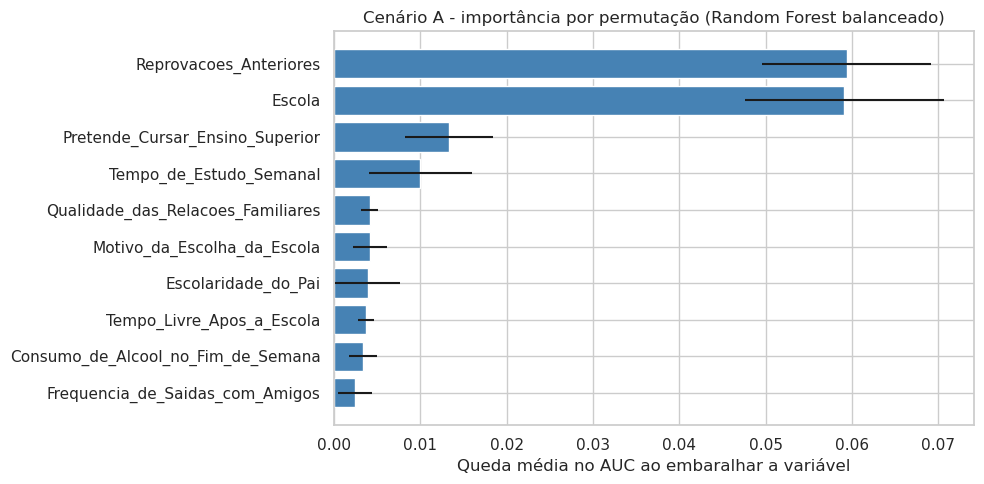

In [43]:
X_tr, _, y_tr, _ = dados("A", "Risco_Reprovacao")
permutacao = permutation_importance(modelos_clf_a[escolhido_clf_a], X_tr, y_tr, scoring="roc_auc",
                                    n_repeats=20, random_state=SEMENTE)
importancia = pd.DataFrame({"Variável": X_tr.columns, "Queda no AUC": permutacao.importances_mean,
                            "Desvio": permutacao.importances_std}).sort_values("Queda no AUC", ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(importancia["Variável"][::-1], importancia["Queda no AUC"][::-1],
         xerr=importancia["Desvio"][::-1], color="steelblue")
plt.title(f"Cenário A - importância por permutação ({escolhido_clf_a})")
plt.xlabel("Queda média no AUC ao embaralhar a variável")
plt.tight_layout(); plt.show()

A importância por permutação não diz se a variável aumenta ou reduz o risco. Para ver a direção, usamos os coeficientes da Logística balanceada, que teve desempenho próximo ao do Random Forest na validação.

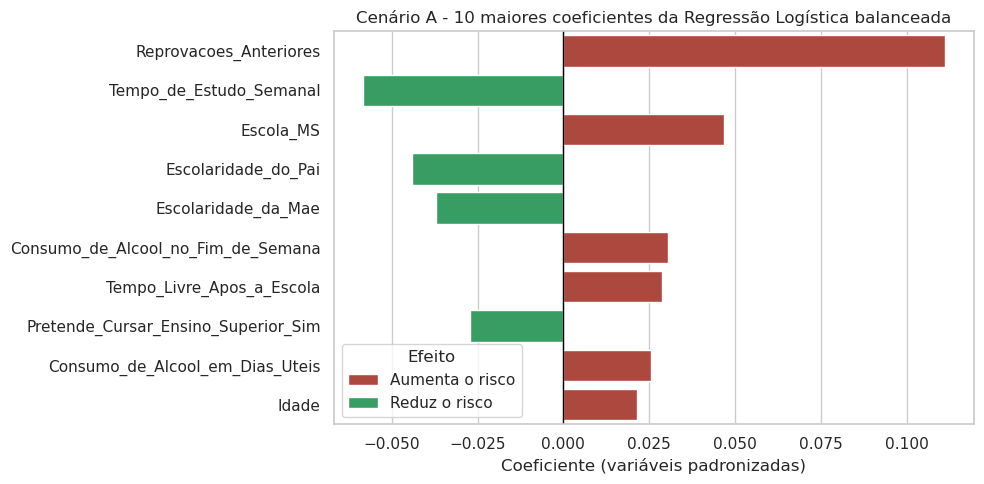

In [44]:
pipe_alerta = modelos_clf_a["Logística balanceada (L2)"]
nomes = [n.replace("num__", "").replace("cat__", "") for n in pipe_alerta.named_steps["prep"].get_feature_names_out()]
coeficientes = pd.DataFrame({"Variável": nomes, "Coeficiente": pipe_alerta.named_steps["modelo"].coef_[0]})
coeficientes["Efeito"] = np.where(coeficientes["Coeficiente"] > 0, "Aumenta o risco", "Reduz o risco")
top = coeficientes.reindex(coeficientes["Coeficiente"].abs().sort_values(ascending=False).index).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top, x="Coeficiente", y="Variável", hue="Efeito",
            palette={"Aumenta o risco": "#c0392b", "Reduz o risco": "#27ae60"}, dodge=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Cenário A - 10 maiores coeficientes da Regressão Logística balanceada")
plt.xlabel("Coeficiente (variáveis padronizadas)"); plt.ylabel("")
plt.tight_layout(); plt.show()

Efeito do balanceamento: no teste do Cenário A, a Logística sem balanceamento encontrou 2 dos 20 reprovados; com `class_weight="balanced"` passou para 11 de 20, e o Random Forest balanceado chegou a 14 de 20. No Cenário B, o recall da Logística foi de 80% para 90%. O custo é uma precisão menor (mais falsos alarmes), aceitável para uma ação de apoio. Não usamos SMOTE nem outra reamostragem: o ajuste de pesos já resolveu o problema sem criar alunos artificiais.

Variáveis mais importantes: as duas medidas apontam para os mesmos fatores. No Random Forest, escola e reprovações anteriores são, de longe, as variáveis de que o modelo mais depende (queda de cerca de 0,06 no AUC cada uma), seguidas de querer cursar o ensino superior e do tempo de estudo. Na Logística, que mostra a direção do efeito, o que mais aumenta o risco é o número de reprovações anteriores e estudar na escola MS; o que mais reduz é o tempo de estudo semanal, a escolaridade do pai e da mãe e querer cursar o ensino superior. Os coeficientes são pequenos por causa da regularização forte, mas podem ser comparados entre si porque as variáveis foram padronizadas.

Esses coeficientes mostram associação, não causa. Estudar na escola MS não causa reprovação; a escola provavelmente reúne outros fatores que a base não mede.

## 6.5 Limitações

* Generalização: são 649 alunos de duas escolas portuguesas, numa única disciplina (Língua Portuguesa) e num único ano de coleta. Para usar em outras escolas, inclusive brasileiras, o modelo teria de ser treinado de novo com dados locais.
* Tamanho do teste: o teste tem só 20 reprovados. Um aluno a mais ou a menos muda o recall em 5 pontos percentuais, então os números devem ser lidos como aproximados. Foi isso que fez a validação e o teste discordarem no Cenário B.
* Faltas fora dos modelos: a base só traz o total de faltas do ano, que não existe no início do ano nem está completo no fim do 2º período. Por isso deixamos as faltas de fora, mesmo sabendo que a frequência é um sinal útil. Com as faltas registradas por período, o modelo poderia melhorar.
* Notas zero: os 15 alunos com nota final zero e nenhuma falta parecem ser abandonos ou ausência na avaliação, mas a base não confirma. Eles concentram os maiores erros da regressão.
* Dados de questionário: tempo de estudo, consumo de álcool, saúde e relação familiar são respostas dos próprios alunos e podem ter viés (por exemplo, subestimar o consumo de álcool).
* Desempenho do Cenário A: sem notas, o modelo explica cerca de 24% da variação da nota, menos da metade dos alunos apontados (42%) de fato reprovaria e, com o mesmo número de indicados, ele não supera regras simples. Ele serve para priorizar quem recebe atenção, não para afirmar que um aluno vai reprovar.
* Limiar de decisão: as tabelas da Etapa 5 usam o corte padrão de 50% de probabilidade. A seção 5.2 mostra que, ordenando os alunos por probabilidade, a escola pode ajustar o tamanho da lista às vagas; não definimos um corte ideal porque isso depende do número de vagas, que a base não informa.
* Uso responsável: variáveis como escola, sexo e situação familiar não devem servir para rotular alunos. A saída do modelo deve virar oferta de apoio, nunca punição ou exclusão.

## 6.6 Conclusão

O projeto apoia uma decisão da coordenação pedagógica: como usar os recursos de apoio (reforço, tutoria, acompanhamento com a família), que são limitados. Cada parte do trabalho responde uma pergunta dessa decisão.

Quem precisa de apoio (classificação). No início do ano, sem nenhuma nota, o Random Forest indicou 33 alunos e encontrou 70% dos que iam reprovar (14 de 20 no teste); de cada 100 indicados, cerca de 42 reprovariam. A regra "quem já reprovou antes" indica 16 alunos e encontra 7. Quando os dois indicam o mesmo número de alunos, porém, encontram a mesma quantidade de reprovados, e a regra "já reprovou antes ou estuda na MS" chega a um resultado parecido com o do modelo. O modelo, portanto, não acerta mais por aluno indicado. O que ele acrescenta é uma lista ordenada por risco, que permite ajustar o número de alunos atendidos às vagas de reforço. Quase todo o sinal disponível no início do ano está em duas informações que a escola já tem: reprovações anteriores e escola.

Quando agir (cenários A e B). No começo do ano, a lista sai do histórico do aluno, pela regra ou pela ordem do modelo. Depois do 2º período, a regra "nota do 2º período abaixo de 10" encontrou 18 dos 20 reprovados no teste. Na validação o Random Forest teve F1 um pouco maior (0,79 contra 0,73), mas a diferença é pequena e não apareceu no teste, então recomendamos a regra, que dispensa modelo. A lista do começo do ano deve ser revisada com ela.

Quanto falta para aprovar (regressão). No início do ano, a nota prevista erra em média 2,22 pontos (R² de 0,24) e chega a 2,75 nos alunos que reprovam, então serve só como indicação aproximada. Depois do 2º período, usar a própria nota do 2º período como previsão é tão bom quanto qualquer modelo: empate na validação e erro médio de 0,75 ponto no teste.

Que tipo de apoio (agrupamento). O grupo 0 (139 alunos) tem 33,1% de reprovação, o dobro da média da base (15,4%), e reúne mais faltas, mais saídas com amigos, mais consumo de álcool no fim de semana e mais reprovações anteriores. É um perfil em que faz sentido conversar sobre rotina e frequência. O grupo 1 (268 alunos, 14,9%) está na média da base e o grupo 2 (242 alunos, 5,8%) tem risco baixo. Como os grupos se sobrepõem (silhueta de 0,10) e usam as faltas do ano inteiro, eles descrevem perfis, mas não servem para classificar alunos no início do ano.

Onde concentrar esforços. A escola MS reprova 30,09% dos alunos, contra 7,57% da GP. Parte disso vem dos 14 alunos da MS com nota final zero (prováveis abandonos), mas mesmo sem eles a diferença continua grande (25,47% contra 7,35%). Quem já reprovou antes tem de 45,71% a 64,29% de reprovação, contra 9,29% de quem nunca reprovou, lembrando que os grupos com 2 e com 3 ou mais reprovações têm só 16 e 14 alunos. São diferenças que a coordenação deveria investigar.

Limites. O resultado vem de 649 alunos de duas escolas portuguesas e de um teste com só 20 reprovados, então os números são aproximados e o modelo precisaria ser treinado de novo para outra escola. As relações encontradas são associações, não causas: não dá para afirmar que reduzir as saídas ou trocar de escola aumentaria a nota. O modelo deve ser usado para priorizar quem recebe atenção, nunca para rotular ou punir.

No fim, o resultado mais útil do projeto foi mostrar, com uma avaliação cuidadosa, que nesta base o risco de reprovação se concentra em poucas informações que a escola já tem. O modelo ajuda a ordenar os alunos por risco no começo do ano, mas não supera regras simples quando os dois indicam o mesmo número de alunos; depois do 2º período, a nota parcial basta.